# EritroFase · Experimento de control: la pérdida física sobre una base polinomial

Experimento complementario al [notebook del equipo](../EritroFase.ipynb), **posterior a la entrega del 11/11/2026**.

**Pregunta.** La entrega compara una INR entrenada con la pérdida física (variantes A y C) contra métodos clásicos que usan *otra* pérdida: el Zernike del código guía y el polinomio con recorte duro de la Definición 11. Esa comparación cambia dos cosas a la vez, la familia de funciones del fondo y la pérdida. Aquí se cambia una sola: se minimiza **la misma pérdida física** (Definiciones 17 y 18, con los hiperparámetros del modelo final) sobre una **base polinomial** de grado 1 a 12. Si la red aporta algo más que su pérdida, sus puntos deben quedar por debajo de la frontera fondo–célula que traza este control.

**Qué necesita.** Los 30 PNG de `data/selection/` y NumPy, SciPy, scikit-image, pandas y matplotlib. No usa PyTorch ni GPU. Las funciones de preprocesamiento, máscaras y métricas se leen del código fuente del notebook del equipo (2.1) y se comprueba que reproducen sus tablas publicadas (2.2).

**Declaraciones.**
- El control se diseñó y ejecutó **después** de la entrega, con los conjuntos de prueba y de generalización ya examinados. No es una evaluación ciega.
- Se reportan **todos los grados**. Ningún grado se elige mirando prueba; cuando hace falta un solo grado se aplica la regla de validación de la sección 8.5 de la entrega.
- Las cifras de Zernike (guía), SIREN (guía), A, C y C con ajuste fino se leen de `results/tables/`. No se recalculan aquí, porque requieren los pesos del modelo y el dataset completo.
- La medida sobre células cortadas por el borde (sección 6) se definió aquí, después de ver los resultados de la sección 4. Es descriptiva.

### Resultado de la corrida registrada

- **Con las métricas de la entrega, la curva del control pasa por los puntos de A y queda por debajo de los de C** en validación, prueba y el otro día (figura 4.3). Con grado 6 (28 coeficientes) deja 5,96 niveles de fondo lento y 1,97 % de cambio de altura en prueba, frente a 6,70 y 3,47 % de C: menos fondo y menos cambio de altura que C en 5 de 5 imágenes de prueba y en 6 de 7 del otro día. Con grado 10 (66 coeficientes) deja 4,75 niveles y 3,28 %, frente a 4,76 y 3,16 % de A.
- **En el mismo espacio de funciones que el Zernike del código guía** (grado 4, 15 coeficientes), la pérdida física deja 6,82 niveles y 1,33 % en prueba, frente a 6,49 y 2,94 %: algo más de fondo y menos de la mitad del cambio de altura.
- **El control no es un método mejor.** M2 evalúa 36 de las 104 células de referencia; las otras 68 están cortadas por el borde del recorte. Ahí el control sí absorbe: con grado 6, 19 de las 68 pierden más del 10 % de altura (ninguna de las 36 interiores) y la peor pierde 42 %. Esa medida no se puede calcular para A, C ni el Zernike, porque sus fondos no están versionados.
- **Qué se puede concluir.** Con M1 y M2, la evidencia de la entrega no distingue la INR de un polinomio ajustado con su misma pérdida. Es consistente con que el aporte medible sea la pérdida física y no la representación neuronal. Para saber si la red se comporta mejor en los bordes hay que medirlo.

## 1. Entorno

Ejecute las celdas en orden, desde la raíz del proyecto o desde `experiments/`. La corrida completa tarda unos minutos en CPU. Tablas y figuras se guardan en `results/control/`.

In [1]:
# 1.1 Importaciones y rutas del proyecto
import ast
import json
import sys
import time
import platform
from pathlib import Path

from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
import scipy
from scipy import ndimage as ndi
import skimage
from skimage.restoration import unwrap_phase

# Jupyter puede iniciar en la raíz del proyecto o en la carpeta experiments.
CWD = Path.cwd().resolve()
ROOT = next((p for p in (CWD, *CWD.parents) if (p / "data/selection/seleccion.csv").is_file()), None)
assert ROOT is not None, "No se encontró data/selection/seleccion.csv: ejecute el notebook dentro del repositorio."
SELECTION_DIR = ROOT / "data" / "selection"
TABLAS_ENTREGA = ROOT / "results" / "tables"
TAB_DIR = ROOT / "results" / "control" / "tables"
FIG_DIR = ROOT / "results" / "control" / "figures"
for carpeta in (TAB_DIR, FIG_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

def guardar_tabla(df: pd.DataFrame, nombre: str, index: bool = False) -> None:
    """Guarda una tabla en results/control/tables/<nombre>.csv."""
    df.to_csv(TAB_DIR / f"{nombre}.csv", index=index)

def guardar_figura(fig, nombre: str) -> None:
    """Guarda una figura ya mostrada en results/control/figures/<nombre>.png."""
    fig.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight")

# Estilo de las figuras: dos tonos categóricos (control y contraste) y tinta neutra para lo publicado.
AZUL, NARANJA, TINTA, TINTA_2, REJILLA = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
                     "legend.fontsize": 9, "image.cmap": "gray", "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA,
                     "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": REJILLA, "grid.linewidth": 0.8, "lines.linewidth": 2})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", None)

entorno = pd.DataFrame.from_dict({
    "Sistema operativo": f"{platform.system()} {platform.release()}", "Arquitectura": platform.machine(),
    "Python": sys.version.split()[0], "NumPy": np.__version__, "SciPy": scipy.__version__,
    "scikit-image": skimage.__version__, "Pandas": pd.__version__, "Matplotlib": matplotlib.__version__,
    "Pillow": PIL.__version__, "Dispositivo": "CPU (sin PyTorch)"}, orient="index", columns=["Valor"])
guardar_tabla(entorno.reset_index(names="Aspecto"), "entorno")
entorno

,Valor
Sistema operativo,Darwin 27.3.0
Arquitectura,arm64
Python,3.13.15
NumPy,2.5.4
SciPy,1.18.1
scikit-image,0.26.0
Pandas,3.1.1
Matplotlib,3.11.2
Pillow,13.0.0
Dispositivo,CPU (sin PyTorch)


## 2. Funciones y datos de la entrega

### 2.1 Mismo código de evaluación

Para que la comparación con las tablas de la entrega sea válida, el control debe usar **exactamente** su preprocesamiento, sus máscaras de referencia y sus métricas. En lugar de copiar esas funciones, la celda siguiente las lee del código fuente de `EritroFase.ipynb` (solo las definiciones de función, sin ejecutar ninguna celda) y las define aquí. Las constantes que esas funciones usan se repiten con los valores de las secciones 3.4, 3.5 y 6.2 de la entrega.

Así el control no puede divergir en silencio del código de la entrega: si una función cambiara, fallaría la verificación de 2.2.

In [2]:
# 2.1 Funciones del notebook del equipo (leídas de su código fuente) y carga de los 30 recortes
FUNCIONES_ENTREGA = ["leer_png", "gris_a_fase_envuelta", "desenvolver", "ajuste_fondo_robusto", "mascara_celulas",
                     "mascaras_referencia", "preprocesar", "base_polinomial", "ajuste_polinomial_robusto",
                     "celulas_evaluables", "fondo_lento", "soporte", "dice", "metricas_imagen"]
fuente = {}
for celda in json.loads((ROOT / "EritroFase.ipynb").read_text(encoding="utf-8"))["cells"]:
    if celda["cell_type"] != "code":
        continue
    codigo = "".join(celda["source"])
    try:
        arbol = ast.parse(codigo)
    except SyntaxError:
        continue
    for nodo in arbol.body:
        if isinstance(nodo, ast.FunctionDef):
            fuente[nodo.name] = ast.get_source_segment(codigo, nodo)

# Constantes de las secciones 3.4, 3.5 y 6.2 de la entrega
NG_POR_RAD = 255 / (2 * np.pi)
H = W = 256
_yy, _xx = np.meshgrid(np.linspace(-1, 1, H), np.linspace(-1, 1, W), indexing="ij")
BASE_POLI = np.stack([np.ones_like(_xx), _xx, _yy, _xx**2, _xx*_yy, _yy**2], -1).reshape(-1, 6)
R_INT, R_EXT, AREA_MIN, SIGMA_SUAVE = 6, 16, 600, 8
for nombre in FUNCIONES_ENTREGA:
    assert nombre in fuente, f"El notebook del equipo ya no define {nombre}"
    exec(fuente[nombre], globals())
BASES_POLI = {d: base_polinomial(d) for d in range(1, 9)}

SELECCION = pd.read_csv(SELECTION_DIR / "seleccion.csv")
CONJUNTOS = ["validacion", "prueba", "generalizacion"]
ETIQUETA = {"validacion": "validación (5)", "prueba": "prueba (5)", "generalizacion": "otro día (8)"}
ARCHIVOS = {c: SELECCION[SELECCION.conjunto == c].archivo.tolist() for c in ["entrenamiento"] + CONJUNTOS}
IMAGENES = {r.archivo: leer_png(SELECTION_DIR / r.conjunto / r.archivo) for r in SELECCION.itertuples()}
PREPROCESADAS = {f: preprocesar(g) for f, g in IMAGENES.items()}
MASCARAS = {f: mascaras_referencia(g) for f, g in IMAGENES.items()}
SIGMA_RUIDO = {f: ajuste_fondo_robusto(desenvolver(g))[2] * NG_POR_RAD for f, g in IMAGENES.items()}
CELULAS_EVAL = {f: celulas_evaluables(*MASCARAS[f]) for f in MASCARAS}
L, DH, ADH = "RMS lento (niveles eq.)", "Δh mediana (%)", "|Δh| mediana (%)"

def metricas_archivo(v: np.ndarray, archivo: str) -> dict:
    """Métricas de una imagen corregida con su referencia, como en la sección 6.2 de la entrega."""
    cel, fon = MASCARAS[archivo]
    return metricas_imagen(v, PREPROCESADAS[archivo], cel, fon, SIGMA_RUIDO[archivo], CELULAS_EVAL[archivo])

print(f"Funciones leídas de EritroFase.ipynb: {len(FUNCIONES_ENTREGA)} · recortes cargados: {len(IMAGENES)}")
print({c: len(a) for c, a in ARCHIVOS.items()})

Funciones leídas de EritroFase.ipynb: 14 · recortes cargados: 30
{'entrenamiento': 12, 'validacion': 5, 'prueba': 5, 'generalizacion': 8}


### 2.2 Verificación: el control reproduce las tablas publicadas

**Criterio, fijado antes de ejecutar:** para el pistón y los polinomios de grado 1 a 3 (los métodos de la entrega que no necesitan PyTorch), las siete métricas por imagen calculadas aquí difieren de las publicadas en `results/tables/` en menos de $10^{-6}$, en validación, prueba y generalización. Lo mismo para $\sigma_{\text{ruido}}$ y el porcentaje de célula de las 30 máscaras. La celda se detiene si no se cumple.

In [3]:
# 2.2 Verificación V1: métricas recalculadas frente a las tablas publicadas de la entrega
TABLA_PUBLICADA = {"validacion": "LB_metricas_validacion_por_imagen.csv", "prueba": "E5_metricas_prueba_por_imagen.csv",
                   "generalizacion": "E6_metricas_generalizacion_por_imagen.csv"}
PUBLICADO = {c: pd.read_csv(TABLAS_ENTREGA / n) for c, n in TABLA_PUBLICADA.items()}

peor, n_comp = 0.0, 0
for conj in CONJUNTOS:
    ref = PUBLICADO[conj].set_index(["archivo", "método"])
    for f in ARCHIVOS[conj]:
        u = PREPROCESADAS[f]
        fondos = {"Pistón": np.full(u.shape, np.median(u)),
                  **{f"Polinomio g{d}": ajuste_polinomial_robusto(u, d) for d in (1, 2, 3)}}
        for metodo, b in fondos.items():
            mias = metricas_archivo(u - b.astype(np.float32), f)       # la entrega guarda los fondos en float32
            for col in (L, DH, ADH, "μ_B", "σ_B", "RMS_B/σ_ruido", "Dice"):
                a, p = mias[col], ref.loc[(f[7:-4], metodo), col]
                if not (np.isnan(a) and np.isnan(p)):
                    peor, n_comp = max(peor, abs(a - p)), n_comp + 1
sigma_pub = pd.read_csv(TABLAS_ENTREGA / "E1_fondo_vs_ruido.csv").set_index("archivo")["σ_ruido (niveles eq.)"]
mask_pub = pd.read_csv(TABLAS_ENTREGA / "E1_mascaras_referencia.csv").set_index("archivo")["% célula"]
dif_sigma = max(abs(SIGMA_RUIDO[f] - sigma_pub[f]) for f in IMAGENES)
dif_mask = max(abs(100 * MASCARAS[f][0].mean() - mask_pub[f]) for f in IMAGENES)
print(f"Métricas por imagen: {n_comp} comparaciones · diferencia absoluta máxima = {peor:.1e}")
print(f"σ_ruido (30 imágenes): diferencia máxima = {dif_sigma:.1e} niveles · % de célula: diferencia máxima = {dif_mask:.1e}")
assert max(peor, dif_sigma, dif_mask) < 1e-6, "El control no reproduce las tablas publicadas de la entrega"
print("V1 SE CUMPLE: el control usa el mismo preprocesamiento, las mismas máscaras y las mismas métricas que la entrega.")

Métricas por imagen: 496 comparaciones · diferencia absoluta máxima = 3.8e-14
σ_ruido (30 imágenes): diferencia máxima = 1.2e-13 niveles · % de célula: diferencia máxima = 0.0e+00
V1 SE CUMPLE: el control usa el mismo preprocesamiento, las mismas máscaras y las mismas métricas que la entrega.


**Lectura de la salida (2.2).** V1 se cumple: en 496 comparaciones la diferencia máxima con las tablas publicadas es $3{,}8 \times 10^{-14}$, y en $\sigma_{\text{ruido}}$, $1{,}2 \times 10^{-13}$ niveles. La entrega se ejecutó en Windows; esta corrida, en otro sistema operativo y con otras versiones de NumPy y SciPy (1.1). El preprocesamiento, las máscaras y las métricas de la entrega se reproducen a precisión de máquina, así que las cifras de este notebook se pueden comparar directamente con las de `results/tables/`.

### 2.3 Hiperparámetros: los del modelo final de la entrega

Se leen de la configuración guardada de la corrida elegida en 8.7.3 (`results/runs/E4_C_w1_ls0.001/config.json`). No se ajusta ninguno. La celda comprueba que el umbral $\tau = 3\hat\sigma$ recalculado desde los 12 recortes de entrenamiento coincide con el guardado.

In [4]:
# 2.3 Hiperparámetros de la pérdida física, leídos de la corrida final de la entrega
CONFIG = json.loads((ROOT / "results" / "runs" / "E4_C_w1_ls0.001" / "config.json").read_text(encoding="utf-8"))
ESCALA_NG, TAU_NG, LAMBDA_S, LAMBDA_SIGNO = CONFIG["escala"], CONFIG["tau"], CONFIG["lambda_s"], CONFIG["lambda_g"]
EPS_CHARB, D_EXCL, N_GRUESA = CONFIG["eps"], CONFIG["d_excl"], CONFIG["malla"]
SIGMA_REF = float(np.median([SIGMA_RUIDO[f] for f in ARCHIVOS["entrenamiento"]]))
assert abs(3.0 * SIGMA_REF - TAU_NG) < 1e-6, "τ recalculado no coincide con el de la corrida final"
pd.DataFrame({"Valor": {"Escala s (niveles por unidad normalizada)": ESCALA_NG, "σ̂ de referencia (niveles)": round(SIGMA_REF, 2),
                        "τ = 3σ̂ (niveles)": round(TAU_NG, 2), "λ_s (suavidad)": LAMBDA_S, "λ_g (signo)": LAMBDA_SIGNO,
                        "ε de Charbonnier": EPS_CHARB, "d de la exclusión por vecindad (px)": D_EXCL,
                        "Malla del laplaciano": f"{N_GRUESA}×{N_GRUESA}"}})

,Valor
Escala s (niveles por unidad normalizada),64.0
σ̂ de referencia (niveles),13.72
τ = 3σ̂ (niveles),41.16
λ_s (suavidad),0.001
λ_g (signo),1.0
ε de Charbonnier,0.01
d de la exclusión por vecindad (px),6
Malla del laplaciano,64×64


## 3. Método: la pérdida de la entrega sobre una base polinomial

> **Definición C1 (fondo polinomial).** Sea $A_g$ la matriz de monomios $x^i y^j$ con $i + j \le g$ sobre la malla $[-1,1]^2$ de 256×256, la misma de la Definición 11 de la entrega, y $A_g = Q_g R_g$ su factorización QR. El fondo normalizado es $\tilde b = Q_g\,\mathbf c$, con $\mathbf c \in \mathbb R^{n_g}$ y $n_g = (g+1)(g+2)/2$. $Q_g$ genera el mismo espacio que los monomios; solo mejora el condicionamiento numérico.

> **Definición C2 (objetivo).** Con $\tilde u = (u - \operatorname{mediana}(u))/s$ y $\tilde r = \tilde u - Q_g\mathbf c$, se minimiza sobre $\mathbf c$ la pérdida de la Definición 17 con los pesos de la Definición 18:
> $$\mathcal L(\mathbf c) = \frac{\sum_i w_i\,\min\{\rho_\epsilon(\tilde r_i),\ \rho_\epsilon(\tau)\}}{\sum_i w_i} \;+\; \lambda_g\,\frac1N\sum_i \max(0,\ -\tilde r_i - \tau)^2 \;+\; \lambda_s\,\frac1M\sum_j \big(\Delta \tilde b\big)_j^2 .$$

> **Definición C3 (solución por mínimos cuadrados reponderados).** En cada iteración se fijan los pesos con el residuo actual y se resuelve un problema cuadrático en $\mathbf c$ cuyo gradiente coincide con el de $\mathcal L$ (con $w_i$ fijo, como en la entrega, que lo calcula sin propagar el gradiente):
> $$\Big(Q^\top \operatorname{diag}(\omega + \omega^{s})\,Q + \tfrac{2\lambda_s}{M}\,D^\top D\Big)\,\mathbf c^\star = Q^\top\big(\omega \odot \tilde u + \omega^{s} \odot (\tilde u + \tau)\big),$$
> $$\omega_i = \frac{w_i\,\mathbb 1[\,|\tilde r_i| < \tau\,]}{\rho_\epsilon(\tilde r_i)\,\sum_k w_k}, \qquad \omega^{s}_i = \frac{2\lambda_g}{N}\,\mathbb 1[\,\tilde r_i < -\tau\,],$$
> donde $D$ es el laplaciano discreto de la base en la malla de 64×64. Las primeras 10 iteraciones son de **calentamiento**, sin recorte ni exclusión ($\omega_i = 1/(N\rho_\epsilon(\tilde r_i))$), como en la entrega. Después se actualiza con amortiguamiento, $\mathbf c \leftarrow \mathbf c + \tfrac12(\mathbf c^\star - \mathbf c)$, hasta que el fondo cambia menos de $10^{-3}$ niveles o se llega a 200 iteraciones.

**Qué es igual y qué cambia respecto a A y C:**

| Aspecto | Entrega (A y C) | Este control |
|---|---|---|
| Pérdida, $\tau$, $d$, $\lambda_s$, $\lambda_g$, $\epsilon$, escala | Definiciones 17–18, configuración final | **Iguales** (leídos de `config.json`) |
| Calentamiento sin recorte ni exclusión | 10 % de los pasos | Las 10 primeras iteraciones |
| Familia de funciones del fondo | SIREN de 33.537 pesos (A) o modulada por un codificador (C) | Polinomio de grado $g$: de 3 a 91 coeficientes |
| Optimizador | Adam, con muestreo de píxeles y semilla | Mínimos cuadrados reponderados: sin semilla ni muestreo |
| Exclusión por vecindad | A: resolución completa. C: media resolución al entrenar | Resolución completa en cada iteración |
| Malla del laplaciano | 64×64 con desplazamiento aleatorio | 64×64 fija |
| Datos de entrenamiento | C: 120 recortes. A: ninguno | Ninguno: se ajusta cada imagen, como A |

El control no es amortizado: ajusta cada imagen por separado, igual que A y que el Zernike. La comparación con C mide calidad, no costo de entrenamiento.

In [5]:
# 3.1 Base polinomial, pérdida física (Definiciones 17–18) y ajuste por mínimos cuadrados reponderados
GRADOS = list(range(1, 13))
IT_CALENTAMIENTO, IT_MAX, AMORTIGUAMIENTO, TOLERANCIA_NG = 10, 200, 0.5, 1e-3

def _monomios(grado: int, n: int) -> np.ndarray:
    """Monomios x^i·y^j con i + j ≤ grado sobre una malla de n×n en [-1, 1]² (mismo orden que base_polinomial)."""
    t = np.linspace(-1, 1, n)
    yy, xx = np.meshgrid(t, t, indexing="ij")
    return np.stack([(xx ** (k - j)) * (yy ** j) for k in range(grado + 1) for j in range(k + 1)], -1).reshape(n * n, -1)

def construir_base(grado: int):
    """Definición C1: base ortonormal Q (256²×n) y su laplaciano discreto en la malla de 64×64 (como en 8.1 de la entrega)."""
    Q, R = np.linalg.qr(_monomios(grado, H))
    B = np.linalg.solve(R.T, _monomios(grado, N_GRUESA).T).T.reshape(N_GRUESA, N_GRUESA, -1)
    h = 2 / (N_GRUESA - 1)
    lap = (B[2:, 1:-1] + B[:-2, 1:-1] + B[1:-1, 2:] + B[1:-1, :-2] - 4 * B[1:-1, 1:-1]) / h ** 2
    return Q, lap.reshape(-1, Q.shape[1])

BASES = {g: construir_base(g) for g in GRADOS}
assert np.allclose(_monomios(3, H), BASES_POLI[3]), "La base no coincide con base_polinomial de la entrega"

def charbonnier(r):
    return np.sqrt(r * r + EPS_CHARB ** 2)

def peso_vecindad(r: np.ndarray, tau: float, d: int) -> np.ndarray:
    """Definición 18: 0 en los píxeles a ≤ d de un residuo > τ (célula probable), 1 en el resto. Imagen completa."""
    grande = (r.reshape(H, W) > tau).astype(float)
    return 1.0 - ndi.maximum_filter(grande, size=2 * d + 1, mode="constant").ravel()

def perdida_fisica(r: np.ndarray, lap_b: np.ndarray, tau: float, d: int = D_EXCL, lam_s: float = LAMBDA_S):
    """Definición 17 con los pesos de la Definición 18. Devuelve (pérdida, fracción de píxeles con peso 1)."""
    w = peso_vecindad(r, tau, d)
    datos = (np.minimum(charbonnier(r), charbonnier(tau)) * w).sum() / max(w.sum(), 1.0)
    signo = LAMBDA_SIGNO * (np.maximum(-r - tau, 0.0) ** 2).mean()
    return float(datos + signo + lam_s * (lap_b ** 2).mean()), float(w.mean())

def ajuste_fisico(u: np.ndarray, grado: int, recorte: bool = True, vecindad: bool = True, signo: bool = True,
                  lam_s: float = LAMBDA_S, kappa: float = None, d: int = D_EXCL, detalle: bool = False):
    """Definición C3: minimiza la pérdida física de la entrega sobre polinomios de grado ≤ grado.
    Los interruptores (recorte, vecindad, signo, lam_s, kappa, d) solo se usan en la ablación de la sección 8."""
    Q, LAP = BASES[grado]
    n = Q.shape[1]
    tau = (TAU_NG if kappa is None else kappa * SIGMA_REF) / ESCALA_NG
    med = float(np.median(u))
    x = ((u - med) / ESCALA_NG).ravel()
    N, M = x.size, LAP.shape[0]
    c = Q.T @ x                                             # inicio: mínimos cuadrados ordinarios
    S = (2 * lam_s / M) * (LAP.T @ LAP)
    paso, it = np.inf, 0
    for it in range(1, IT_CALENTAMIENTO + IT_MAX + 1):
        r = x - Q @ c
        calentando = it <= IT_CALENTAMIENTO
        if calentando or not recorte:                       # Charbonnier completa
            om = 1.0 / charbonnier(r) / N
        else:
            w = peso_vecindad(r, tau, d) if vecindad else np.ones(N)
            om = np.where(np.abs(r) < tau, w / charbonnier(r), 0.0) / max(w.sum(), 1.0)
        om_s = np.where(r < -tau, 2 * LAMBDA_SIGNO / N, 0.0) if signo else np.zeros(N)
        G = (Q * (om + om_s)[:, None]).T @ Q + S + 1e-12 * np.eye(n)
        c_nueva = np.linalg.solve(G, Q.T @ (om * x + om_s * (x + tau)))
        if not calentando:
            c_nueva = c + AMORTIGUAMIENTO * (c_nueva - c)
        paso = float(np.abs(Q @ (c_nueva - c)).max() * ESCALA_NG)
        c = c_nueva
        if not calentando and paso < TOLERANCIA_NG:
            break
    fondo = (Q @ c * ESCALA_NG + med).reshape(u.shape)
    if not detalle:
        return fondo
    perdida, frac = perdida_fisica(x - Q @ c, LAP @ c, tau, d, lam_s)
    return fondo, {"iteraciones": it, "paso final (niveles)": paso, "pérdida": perdida, "píxeles con peso 1 (%)": 100 * frac}

# Verificación V2: los 15 términos de Zernike del código guía generan el mismo espacio que los polinomios de grado ≤ 4
fuente_guia = (ROOT / "reference_code" / "INR" / "unwrapper.py").read_text(encoding="utf-8")
nodo_zernike = next(n for n in ast.parse(fuente_guia).body if isinstance(n, ast.FunctionDef) and n.name == "build_zernike_basis")
exec(ast.get_source_segment(fuente_guia, nodo_zernike), globals())
Z15 = build_zernike_basis(H, W, 15)[0]
Q4 = BASES[4][0]
residuo_zernike = float(np.abs(Z15 - Q4 @ (Q4.T @ Z15)).max())
assert np.linalg.matrix_rank(Z15) == 15 and residuo_zernike < 1e-8, "El Zernike de 15 términos no coincide con el espacio de grado 4"

print("Coeficientes por grado:", {g: BASES[g][0].shape[1] for g in GRADOS})
print(f"V2 SE CUMPLE: los 15 términos de Zernike del código guía tienen rango 15 y quedan dentro del espacio de grado 4 "
      f"(residuo máximo de la proyección = {residuo_zernike:.1e}).")

Coeficientes por grado: {1: 3, 2: 6, 3: 10, 4: 15, 5: 21, 6: 28, 7: 36, 8: 45, 9: 55, 10: 66, 11: 78, 12: 91}
V2 SE CUMPLE: los 15 términos de Zernike del código guía tienen rango 15 y quedan dentro del espacio de grado 4 (residuo máximo de la proyección = 2.7e-12).


## 4. Frontera fondo–célula del control

Se ajusta cada imagen de validación, prueba y generalización con grados 1 a 12 y se calculan M1 (RMS del fondo lento) y M2 ($\lvert\Delta h\rvert$ mediano) con las funciones de la entrega. Como contraste se incluye el polinomio con recorte duro de la Definición 11 (la línea base L1 de la entrega) hasta grado 8: misma base, otra pérdida.

**Lo que se espera si la red aporta más que su pérdida:** los puntos de A y C quedan abajo y a la izquierda de la curva del control. **Si no aporta:** quedan sobre la curva o por encima.

In [6]:
# 4.1 Ajuste de las 18 imágenes de evaluación con grados 1 a 12 (control) y 1 a 8 (recorte duro de la Definición 11)
CONTROL, DURO = "Polinomio + pérdida física (control)", "Polinomio con recorte duro (Def. 11)"
FONDOS, filas = {}, []
t_inicio = time.perf_counter()
for conj in CONJUNTOS:
    for f in ARCHIVOS[conj]:
        u = PREPROCESADAS[f]
        for g in GRADOS:
            t0 = time.perf_counter()
            b, info = ajuste_fisico(u, g, detalle=True)
            t = time.perf_counter() - t0
            FONDOS[(f, g)] = b
            filas.append({"conjunto": conj, "archivo": f[7:-4], "método": CONTROL, "grado": g,
                          "coeficientes": BASES[g][0].shape[1], "tiempo (s)": t, **info, **metricas_archivo(u - b, f)})
        for g in range(1, 9):
            t0 = time.perf_counter()
            b = ajuste_polinomial_robusto(u, g)
            filas.append({"conjunto": conj, "archivo": f[7:-4], "método": DURO, "grado": g,
                          "coeficientes": BASES[g][0].shape[1], "tiempo (s)": time.perf_counter() - t0, **metricas_archivo(u - b, f)})
FRONTERA = pd.DataFrame(filas)
guardar_tabla(FRONTERA, "C1_frontera_por_imagen")
print(f"Ajustes: {len(FRONTERA)} en {time.perf_counter() - t_inicio:.0f} s")

def resumen_por_grado(metodo: str) -> pd.DataFrame:
    t = FRONTERA[FRONTERA["método"] == metodo]
    r = t.groupby(["grado", "conjunto"])[[L, ADH]].median().unstack("conjunto")
    r = r.reindex(columns=[(m, c) for c in CONJUNTOS for m in (L, ADH)])
    r.columns = [f"{'M1' if m == L else 'M2 (%)'} · {ETIQUETA[c]}" for m, c in r.columns]
    r.insert(0, "coeficientes", t.groupby("grado")["coeficientes"].first())
    return r

RESUMEN_CONTROL, RESUMEN_DURO = resumen_por_grado(CONTROL), resumen_por_grado(DURO)
guardar_tabla(RESUMEN_CONTROL.reset_index(), "C1_frontera_control")
guardar_tabla(RESUMEN_DURO.reset_index(), "C1_frontera_recorte_duro")
print("Control: polinomio + pérdida física de la entrega (medianas por imagen; M1 en niveles eq.)")
display(RESUMEN_CONTROL.round(2))
print("Contraste: polinomio con recorte duro de la Definición 11 (línea base L1 de la entrega)")
display(RESUMEN_DURO.round(2))

# Lo publicado por la entrega, en las mismas imágenes
METODOS_PUB = ["Zernike (guía)", "SIREN ω0=1 (guía)", "SIREN por imagen + física (A)", "INR condicionada (C)", "C + ajuste fino (100 it.)"]
val_final = pd.read_csv(TABLAS_ENTREGA / "E5_validacion_modelo_final.csv").set_index("método")[[L, ADH]]
MEDIANAS_PUB = {"validacion": val_final.loc[METODOS_PUB],
                **{c: PUBLICADO[c].groupby("método")[[L, ADH]].median().loc[METODOS_PUB] for c in ("prueba", "generalizacion")}}
pub = pd.concat({ETIQUETA[c]: MEDIANAS_PUB[c].rename(columns={L: "M1", ADH: "M2 (%)"}) for c in CONJUNTOS}, axis=1)
pub_plana = pub.copy(); pub_plana.columns = [f"{m} · {c}" for c, m in pub.columns]
guardar_tabla(pub_plana.reset_index(), "C1_publicado_entrega")
print("Publicado por la entrega (results/tables/), mismas imágenes y mismas métricas")
display(pub.round(2))

Ajustes: 360 en 92 s
Control: polinomio + pérdida física de la entrega (medianas por imagen; M1 en niveles eq.)


,coeficientes,M1 · validación (5),M2 (%) · validación (5),M1 · prueba (5),M2 (%) · prueba (5),M1 · otro día (8),M2 (%) · otro día (8)
grado,,,,,,,
1,3,16.13,0.10,14.08,0.13,12.98,0.12
2,6,11.69,0.58,11.45,0.54,10.33,0.55
3,10,7.99,0.86,8.69,0.69,7.48,1.20
4,15,6.61,1.16,6.82,1.33,6.22,2.07
5,21,6.20,1.89,6.51,1.45,5.40,2.88
6,28,5.76,1.95,5.96,1.97,4.66,3.81
7,36,5.11,2.33,5.87,2.38,4.20,4.38
8,45,5.01,3.70,5.49,2.73,3.82,4.74
9,55,4.64,3.91,5.19,3.15,3.68,5.10


Contraste: polinomio con recorte duro de la Definición 11 (línea base L1 de la entrega)


,coeficientes,M1 · validación (5),M2 (%) · validación (5),M1 · prueba (5),M2 (%) · prueba (5),M1 · otro día (8),M2 (%) · otro día (8)
grado,,,,,,,
1,3,15.80,0.26,14.12,0.19,13.91,0.17
2,6,12.81,0.98,10.62,0.73,10.35,0.56
3,10,7.90,1.37,10.37,1.19,9.29,2.01
4,15,6.78,2.21,7.10,2.89,8.31,4.50
5,21,9.23,2.48,7.19,2.83,7.12,5.20
6,28,10.53,6.04,8.63,4.94,6.40,8.71
7,36,11.49,9.77,12.56,11.56,6.79,15.23
8,45,11.64,13.61,12.80,18.27,8.52,19.01


Publicado por la entrega (results/tables/), mismas imágenes y mismas métricas


validación (5)        prueba (5)        otro día (8)       
                                          M1 M2 (%)         M1 M2 (%)           M1 M2 (%)
método                                                                                   
Zernike (guía)                          6.39   2.55       6.49   2.94         5.98   4.60
SIREN ω0=1 (guía)                       3.54  12.80       4.23  12.29         3.83  12.53
SIREN por imagen + física (A)           4.67   4.76       4.76   3.16         3.74   5.07
INR condicionada (C)                    5.69   3.21       6.70   3.47         4.88   5.45
C + ajuste fino (100 it.)               5.01   4.50       5.12   3.54         3.83   5.67

In [7]:
# 4.2 Convergencia y costo del ajuste del control
t = FRONTERA[FRONTERA["método"] == CONTROL]
CONVERGENCIA = t.groupby("grado").agg(
    coeficientes=("coeficientes", "first"),
    iteraciones_mediana=("iteraciones", "median"),
    sin_converger=("paso final (niveles)", lambda s: int((s >= TOLERANCIA_NG).sum())),
    paso_final_max=("paso final (niveles)", "max"),
    peso_1_mediana=("píxeles con peso 1 (%)", "median"),
    tiempo_mediano_s=("tiempo (s)", "median"))
CONVERGENCIA.columns = ["coeficientes", "iteraciones (mediana)", f"imágenes sin converger (de {t.groupby('grado').size().iloc[0]})",
                        "paso final máximo (niveles)", "píxeles con peso 1 (%, mediana)", "tiempo por imagen (s, mediana)"]
guardar_tabla(CONVERGENCIA.reset_index(), "C1_convergencia")
display(CONVERGENCIA.round(3))

,coeficientes,iteraciones (mediana),imágenes sin converger (de 18),paso final máximo (niveles),"píxeles con peso 1 (%, mediana)","tiempo por imagen (s, mediana)"
grado,,,,,,
1,3,81.0,1,0.063,59.148,0.132
2,6,90.5,0,0.001,61.182,0.160
3,10,81.5,0,0.001,63.409,0.131
4,15,82.5,1,0.003,64.982,0.140
5,21,80.0,1,0.009,65.091,0.181
6,28,78.5,0,0.001,65.694,0.209
7,36,80.5,3,0.049,65.936,0.272
8,45,75.0,3,0.240,66.232,0.288
9,55,83.5,2,0.006,66.247,0.377


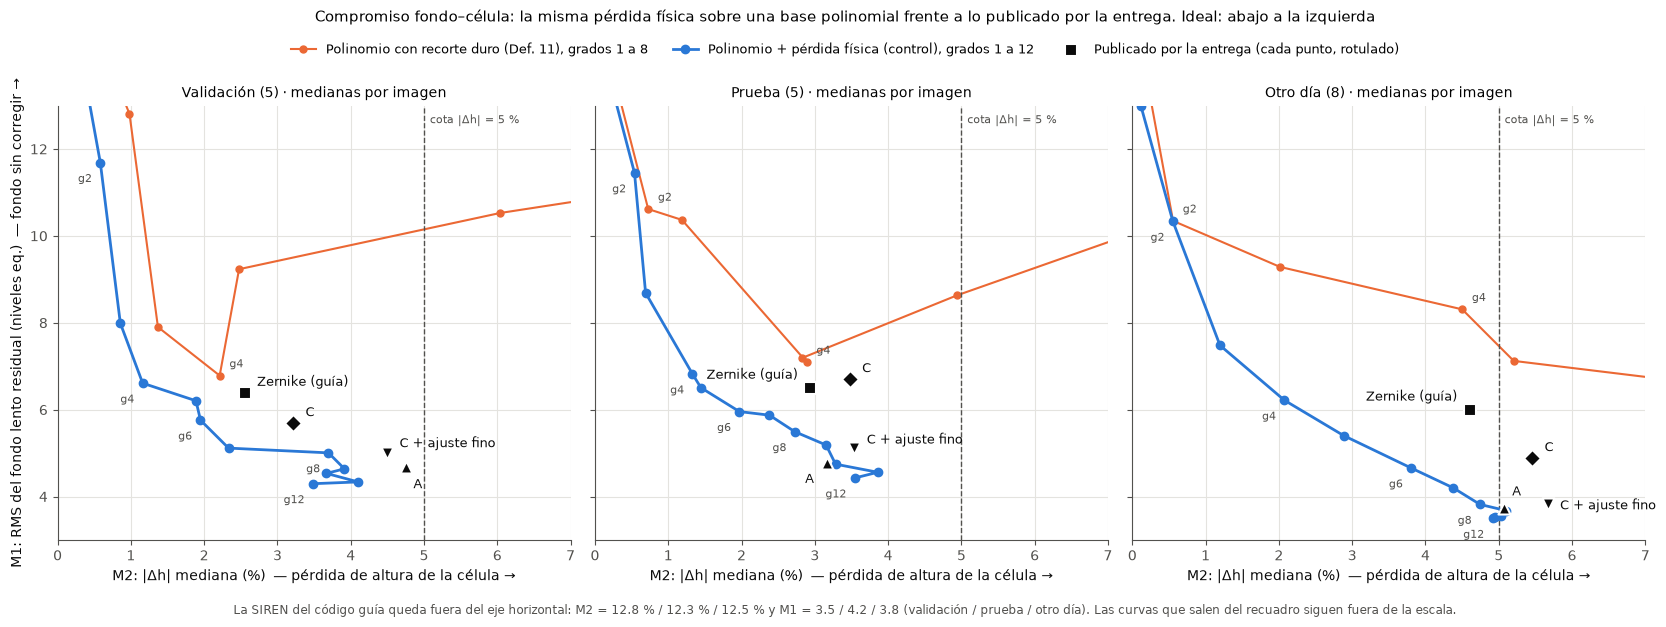

In [8]:
# 4.3 Figura: compromiso fondo–célula. Curva del control por grado frente a los puntos publicados por la entrega
MARCA_PUB = {"Zernike (guía)": ("s", "Zernike (guía)"), "SIREN por imagen + física (A)": ("^", "A"),
             "INR condicionada (C)": ("D", "C"), "C + ajuste fino (100 it.)": ("v", "C + ajuste fino")}
# Posición de cada rótulo respecto a su marcador (puntos; alineación), elegida por panel para que no tape curvas ni marcas
ROTULO = {"validacion": {"Zernike (guía)": (9, 5, "left"), "INR condicionada (C)": (9, 5, "left"),
                         "C + ajuste fino (100 it.)": (9, 4, "left"), "SIREN por imagen + física (A)": (5, -15, "left")},
          "prueba": {"Zernike (guía)": (-9, 7, "right"), "INR condicionada (C)": (9, 5, "left"),
                     "C + ajuste fino (100 it.)": (9, 3, "left"), "SIREN por imagen + física (A)": (-9, -14, "right")},
          "generalizacion": {"Zernike (guía)": (-9, 7, "right"), "INR condicionada (C)": (9, 5, "left"),
                             "C + ajuste fino (100 it.)": (9, -4, "left"), "SIREN por imagen + física (A)": (6, 9, "left")}}
GRADOS_ROTULADOS = (2, 4, 6, 8, 12)
fig, ax = plt.subplots(1, 3, figsize=(17, 6.2), sharex=True, sharey=True)
for a, conj in zip(ax, CONJUNTOS):
    c = FRONTERA[(FRONTERA["método"] == CONTROL) & (FRONTERA.conjunto == conj)].groupby("grado")[[L, ADH]].median()
    d = FRONTERA[(FRONTERA["método"] == DURO) & (FRONTERA.conjunto == conj)].groupby("grado")[[L, ADH]].median()
    a.plot(d[ADH], d[L], "-o", color=NARANJA, ms=5, lw=1.5, label=DURO + ", grados 1 a 8", zorder=2)
    a.plot(c[ADH], c[L], "-o", color=AZUL, ms=6, label=CONTROL + ", grados 1 a 12", zorder=3)
    for g in GRADOS_ROTULADOS:
        a.annotate(f"g{g}", (c.loc[g, ADH], c.loc[g, L]), xytext=(-6, -14), textcoords="offset points", fontsize=8, color=TINTA_2, ha="right")
    for g in (2, 4):
        if d.loc[g, ADH] < 6.6 and d.loc[g, L] < 12.6:
            a.annotate(f"g{g}", (d.loc[g, ADH], d.loc[g, L]), xytext=(7, 6), textcoords="offset points", fontsize=8, color=TINTA_2)
    for m, (marca, rotulo) in MARCA_PUB.items():
        x, y = MEDIANAS_PUB[conj].loc[m, ADH], MEDIANAS_PUB[conj].loc[m, L]
        a.scatter([x], [y], marker=marca, s=75, color=TINTA, edgecolor="white", linewidth=1.5, zorder=4,
                  label="Publicado por la entrega (cada punto, rotulado)" if m == "Zernike (guía)" else None)
        dx, dy, ha = ROTULO[conj][m]
        a.annotate(rotulo, (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=TINTA, ha=ha)
    a.axvline(5, color=TINTA_2, ls="--", lw=1)
    a.text(5.08, 12.8, "cota |Δh| = 5 %", fontsize=8, color=TINTA_2, va="top")
    a.set_title(ETIQUETA[conj][0].upper() + ETIQUETA[conj][1:] + " · medianas por imagen")
    a.set_xlabel("M2: |Δh| mediana (%)  — pérdida de altura de la célula →")
    a.grid(True); a.set_axisbelow(True)
ax[0].set_ylabel("M1: RMS del fondo lento residual (niveles eq.)  — fondo sin corregir →")
ax[0].set_xlim(0, 7); ax[0].set_ylim(3, 13)
manijas, nombres = ax[0].get_legend_handles_labels()
fig.legend(manijas, nombres, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.945))
fig.suptitle("Compromiso fondo–célula: la misma pérdida física sobre una base polinomial frente a lo publicado por la entrega. Ideal: abajo a la izquierda", fontsize=11)
sg = {c: MEDIANAS_PUB[c].loc["SIREN ω0=1 (guía)"] for c in CONJUNTOS}
fig.text(0.5, 0.005, "La SIREN del código guía queda fuera del eje horizontal: M2 = " + " / ".join(f"{sg[c][ADH]:.1f} %" for c in CONJUNTOS)
         + " y M1 = " + " / ".join(f"{sg[c][L]:.1f}" for c in CONJUNTOS) + " (validación / prueba / otro día). "
         "Las curvas que salen del recuadro siguen fuera de la escala.", ha="center", fontsize=8.5, color=TINTA_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.93)); plt.show()
guardar_figura(fig, "C1_compromiso_fondo_celula")

**Lectura de la salida (sección 4).** Medianas por imagen; M1 en niveles equivalentes y M2 en %.

| Método | Coeficientes por imagen | Validación | Prueba | Otro día |
|---|---:|---|---|---|
| Zernike (guía) | 15 | 6,39 / 2,55 | 6,49 / 2,94 | 5,98 / 4,60 |
| Control, grado 4 | 15 | 6,61 / 1,16 | 6,82 / 1,33 | 6,22 / 2,07 |
| C (modelo final de la entrega) | 0 (284.033 compartidos) | 5,69 / 3,21 | 6,70 / 3,47 | 4,88 / 5,45 |
| Control, grado 6 | 28 | 5,76 / 1,95 | 5,96 / 1,97 | 4,66 / 3,81 |
| C + ajuste fino | 34.305 | 5,01 / 4,50 | 5,12 / 3,54 | 3,83 / 5,67 |
| Control, grado 8 | 45 | 5,01 / 3,70 | 5,49 / 2,73 | 3,82 / 4,74 |
| A | 33.537 | 4,67 / 4,76 | 4,76 / 3,16 | 3,74 / 5,07 |
| Control, grado 10 | 66 | 4,53 / 3,67 | 4,75 / 3,28 | 3,56 / 5,03 |
| Control, grado 12 | 91 | 4,30 / 3,48 | 4,43 / 3,54 | 3,50 / 4,92 |

- **La pérdida, y no la base, limitaba a la línea base polinomial.** Con el recorte duro de la Definición 11 el ajuste se degrada a partir de grado 5: en validación pasa de 6,78 niveles y 2,21 % (grado 4) a 10,53 y 6,04 % (grado 6) y a 11,64 y 13,61 % (grado 8). Con la pérdida física, la misma base sigue bajando M1 hasta grado 12 con M2 por debajo del 5 % en validación y en prueba.
- **Mismo espacio que el Zernike (grado 4).** La celda 3.1 comprueba que los 15 términos de Zernike del código guía generan exactamente los polinomios de grado ≤ 4. Con la pérdida física, ese espacio deja entre 0,2 y 0,3 niveles más de fondo lento que el Zernike del código guía y alrededor de la mitad de su cambio de altura (1,16 frente a 2,55 %; 1,33 frente a 2,94 %; 2,07 frente a 4,60 %).
- **C queda por encima de la curva en los tres conjuntos.** Con un fondo lento parecido al de C, el control de grado 6 cambia menos la altura (1,95 frente a 3,21 %; 1,97 frente a 3,47 %; 3,81 frente a 5,45 %). En prueba, además, deja menos fondo (5,96 frente a 6,70 niveles).
- **A queda sobre la curva.** El grado 10 da 4,75 niveles y 3,28 % en prueba, frente a 4,76 y 3,16 % de A. En el otro día, el grado 9 da 3,68 y 5,10 %, frente a 3,74 y 5,07 %. Con estos datos no se distinguen.
- **Convergencia.** Los grados 2, 3 y 6 convergen en las 18 imágenes (el fondo cambia menos de 0,001 niveles en el último paso). A partir de grado 7, entre 2 y 5 imágenes no alcanzan la tolerancia en 200 iteraciones y el último paso llega a 1,05 niveles con grado 12. La pérdida no es convexa y la máscara de exclusión cambia de forma discreta, así que no hay garantía de punto fijo. Las cifras de los grados altos tienen esa incertidumbre añadida.
- **Costo.** Cada ajuste tarda entre ≈ 0,1 y ≈ 0,5 s en la CPU de 1.1, con NumPy y sin optimizar. No se compara con los tiempos de la entrega, medidos en otro equipo.

**Límite:** son las mismas 5, 5 y 8 imágenes de la entrega, y este control se hizo después de conocer sus resultados en prueba y en el otro día.

## 5. Comparación por imagen con los métodos de la entrega

Las medianas pueden ocultar lo que pasa imagen por imagen. Para cada grado del control se cuenta, en prueba y en generalización, en cuántas imágenes deja menos fondo lento (M1), menos cambio de altura (M2) y ambas cosas a la vez que cada método publicado. Es la condición 3 del criterio de éxito de 6.5, aplicada al control. En validación la entrega solo publica medianas de A y C, así que no se puede contar por imagen.

Después se aplica al control la regla de selección de 8.5 de la entrega: entre los grados con $\lvert\Delta h\rvert$ mediana ≤ 5 % en validación, el de menor M1.

In [9]:
# 5.1 Conteo por imagen: control (cada grado) frente a cada método publicado, en prueba y generalización
REFERENCIAS = ["Zernike (guía)", "INR condicionada (C)", "SIREN por imagen + física (A)", "C + ajuste fino (100 it.)"]
filas = []
for conj in ("prueba", "generalizacion"):
    pub_l = PUBLICADO[conj].pivot(index="archivo", columns="método", values=L)
    pub_a = PUBLICADO[conj].pivot(index="archivo", columns="método", values=ADH)
    for g in GRADOS:
        mio = FRONTERA[(FRONTERA["método"] == CONTROL) & (FRONTERA.conjunto == conj) & (FRONTERA.grado == g)].set_index("archivo")
        for ref in REFERENCIAS:
            con_m2 = mio[ADH].notna() & pub_a[ref].notna()
            menos_l, menos_a = mio[L] < pub_l[ref], (mio[ADH] < pub_a[ref]) & con_m2
            filas.append({"conjunto": conj, "grado": g, "referencia": ref, "imágenes": len(mio), "imágenes con M2": int(con_m2.sum()),
                          "control con menos M1": int(menos_l.sum()), "control con menos M2": int(menos_a.sum()),
                          "control mejor en ambas": int((menos_l & menos_a).sum())})
POR_IMAGEN = pd.DataFrame(filas)
guardar_tabla(POR_IMAGEN, "C2_comparacion_por_imagen")

def texto(fila) -> str:
    return f"{fila['control con menos M1']}/{fila['imágenes']} · {fila['control con menos M2']}/{fila['imágenes con M2']} · {fila['control mejor en ambas']}/{fila['imágenes con M2']}"
for conj in ("prueba", "generalizacion"):
    t = POR_IMAGEN[POR_IMAGEN.conjunto == conj].assign(celda=lambda d: d.apply(texto, axis=1))
    print(f"{ETIQUETA[conj]}: imágenes en que el control tiene menos M1 · menos M2 · mejora ambas, frente a cada método publicado")
    display(t.pivot(index="grado", columns="referencia", values="celda")[REFERENCIAS])

# 5.2 Regla de selección de 8.5 de la entrega, aplicada al control en validación
val = FRONTERA[(FRONTERA["método"] == CONTROL) & (FRONTERA.conjunto == "validacion")].groupby("grado")[[L, ADH]].median()
aptos = val[val[ADH] <= 5]
GRADO_REGLA = int(aptos[L].idxmin())
print(f"Regla de 8.5 (|Δh| ≤ 5 % en validación → menor M1): grado {GRADO_REGLA} "
      f"(M1 = {val.loc[GRADO_REGLA, L]:.2f}, M2 = {val.loc[GRADO_REGLA, ADH]:.2f} %). Grados que cumplen la cota: {list(aptos.index)}")
print("El grado elegido es el mayor del intervalo explorado:", GRADO_REGLA == max(GRADOS))

prueba (5): imágenes en que el control tiene menos M1 · menos M2 · mejora ambas, frente a cada método publicado


referencia,Zernike (guía),INR condicionada (C),SIREN por imagen + física (A),C + ajuste fino (100 it.)
grado,,,,
1,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5
2,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5
3,0/5 · 4/5 · 0/5,1/5 · 5/5 · 1/5,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5
4,0/5 · 4/5 · 0/5,2/5 · 5/5 · 2/5,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5
5,2/5 · 4/5 · 1/5,2/5 · 5/5 · 2/5,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5
6,5/5 · 4/5 · 4/5,5/5 · 5/5 · 5/5,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5
7,5/5 · 3/5 · 3/5,4/5 · 5/5 · 4/5,0/5 · 5/5 · 0/5,0/5 · 5/5 · 0/5
8,5/5 · 2/5 · 2/5,5/5 · 4/5 · 4/5,3/5 · 4/5 · 2/5,3/5 · 5/5 · 3/5
9,5/5 · 1/5 · 1/5,5/5 · 2/5 · 2/5,3/5 · 3/5 · 2/5,4/5 · 5/5 · 4/5


otro día (8): imágenes en que el control tiene menos M1 · menos M2 · mejora ambas, frente a cada método publicado


referencia,Zernike (guía),INR condicionada (C),SIREN por imagen + física (A),C + ajuste fino (100 it.)
grado,,,,
1,0/8 · 7/7 · 0/7,0/8 · 7/7 · 0/7,0/8 · 7/7 · 0/7,0/8 · 7/7 · 0/7
2,0/8 · 7/7 · 0/7,1/8 · 7/7 · 0/7,0/8 · 7/7 · 0/7,0/8 · 7/7 · 0/7
3,1/8 · 7/7 · 0/7,1/8 · 7/7 · 0/7,1/8 · 7/7 · 0/7,1/8 · 7/7 · 0/7
4,5/8 · 7/7 · 5/7,1/8 · 7/7 · 1/7,0/8 · 7/7 · 0/7,0/8 · 7/7 · 0/7
5,8/8 · 7/7 · 7/7,4/8 · 7/7 · 3/7,1/8 · 7/7 · 0/7,1/8 · 7/7 · 0/7
6,8/8 · 5/7 · 5/7,7/8 · 7/7 · 6/7,1/8 · 7/7 · 0/7,1/8 · 7/7 · 0/7
7,8/8 · 3/7 · 3/7,7/8 · 6/7 · 5/7,1/8 · 7/7 · 0/7,1/8 · 7/7 · 0/7
8,8/8 · 2/7 · 2/7,8/8 · 4/7 · 4/7,2/8 · 5/7 · 1/7,5/8 · 5/7 · 2/7
9,8/8 · 0/7 · 0/7,8/8 · 4/7 · 4/7,5/8 · 5/7 · 3/7,8/8 · 5/7 · 5/7


Regla de 8.5 (|Δh| ≤ 5 % en validación → menor M1): grado 12 (M1 = 4.30, M2 = 3.48 %). Grados que cumplen la cota: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
El grado elegido es el mayor del intervalo explorado: True


**Lectura de la salida (sección 5).** Cada celda de la tabla da tres conteos: imágenes en que el control deja menos fondo lento (M1), en que cambia menos la altura (M2) y en que hace las dos cosas.

- **Frente a C.** Con grado 6, el control mejora las dos métricas en 5 de 5 imágenes de prueba y en 6 de 7 del otro día. Con grado 8, en 4 de 5 y en 4 de 7.
- **Frente al Zernike (guía).** Con grado 6, mejora ambas en 4 de 5 imágenes de prueba y en 5 de 7 del otro día; con grado 5, en 7 de 7 del otro día. Ningún método de la entrega superó al Zernike en las dos métricas en más de 1 de 5 imágenes de prueba (9.1).
- **Frente a A.** En prueba ningún grado mejora las dos métricas en más de 2 de 5 imágenes: con grado bajo el control conserva mejor la altura y deja más fondo, y con grado alto ocurre lo contrario. En el otro día, los grados 11 y 12 mejoran ambas en 6 de 7. Es lo que se espera de dos métodos sobre la misma frontera.
- **La regla de 8.5 no se satura.** Los 12 grados cumplen $\lvert\Delta h\rvert \le 5\,\%$ en validación, así que la regla elige el de menor M1, que es el mayor grado explorado (12). Una regla que siempre elige el extremo del intervalo no está limitando la flexibilidad. La sección 6 muestra qué deja de ver.

**Límite:** con 5 imágenes, una prueba pareada de Wilcoxon bilateral no puede dar un valor p menor que 0,0625, ni siquiera con 5 de 5. Estos conteos son descriptivos.

## 6. Lo que M2 no ve: las células cortadas por el borde

La Definición 12 de la entrega solo evalúa células a 16 píxeles o más del borde del recorte. La regla de 8.5 eligió el mayor grado explorado, y un polinomio de grado alto tiene libertad para subir justo en los bordes y las esquinas, donde hay poco fondo que lo sujete. Si eso ocurre bajo una célula cortada por el borde, M2 no lo registra.

> **Definición C4 (cambio de altura en células de borde; descriptiva y definida después de ver la sección 4).** Para cada componente de la máscara de referencia con al menos 600 píxeles que queda a menos de 16 píxeles del borde, se calcula el mismo $\Delta h_j$ de la Definición 14, con el anillo $R_j = D_{16}(C_j) \cap B$ recortado por el borde de la imagen. Se exige que el anillo tenga al menos 200 píxeles.

Es menos confiable que M2: el anillo es parcial y no rodea a la célula, así que la Proposición 5 (invariancia ante errores afines) no se cumple. Sirve para comparar grados entre sí con la misma regla, no como cifra absoluta.

**Límite importante.** Solo puede calcularse para los métodos cuyo fondo se puede reconstruir aquí. Los fondos de A, C y el Zernike no están versionados, de modo que esta sección no dice nada sobre ellos. La entrega reporta el mismo modo de falla para C de forma cualitativa (9.3, 9.4 y 10.2).

In [10]:
# 6.1 Células evaluables por M2 frente a células cortadas por el borde, y Δh en unas y otras
def celulas_de_borde(cel: np.ndarray, fon: np.ndarray, anillo_min: int = 200) -> list:
    """Definición C4: componentes con área ≥ AREA_MIN a menos de R_EXT del borde, con su anillo parcial dentro del fondo."""
    lab, n = ndi.label(cel)
    salida = []
    for j in range(1, n + 1):
        cj = lab == j
        if cj.sum() < AREA_MIN:
            continue
        ys, xs = np.nonzero(cj)
        if not (ys.min() < R_EXT or xs.min() < R_EXT or ys.max() >= cel.shape[0] - R_EXT or xs.max() >= cel.shape[1] - R_EXT):
            continue
        anillo = ndi.binary_dilation(cj, iterations=R_EXT) & fon
        if anillo.sum() >= anillo_min:
            salida.append((cj, anillo))
    return salida

CELULAS_BORDE = {f: celulas_de_borde(*MASCARAS[f]) for f in MASCARAS}

def n_componentes(f: str) -> int:
    lab, n = ndi.label(MASCARAS[f][0])
    return int((ndi.sum(MASCARAS[f][0], lab, range(1, n + 1)) >= AREA_MIN).sum()) if n else 0

conteo = pd.DataFrame([{"conjunto": ETIQUETA[c], "componentes ≥ 600 px": sum(n_componentes(f) for f in ARCHIVOS[c]),
                        "evaluables por M2 (Def. 12)": sum(len(CELULAS_EVAL[f]) for f in ARCHIVOS[c]),
                        "de borde (Def. C4)": sum(len(CELULAS_BORDE[f]) for f in ARCHIVOS[c])} for c in CONJUNTOS]).set_index("conjunto")
conteo.loc["total"] = conteo.sum()
guardar_tabla(conteo.reset_index(), "C3_conteo_celulas")
display(conteo)

DURO_G3 = "Polinomio g3 con recorte duro (línea base)"
filas = []
for conj in CONJUNTOS:
    for f in ARCHIVOS[conj]:
        u = PREPROCESADAS[f]
        metodos = {("Pistón", 0): np.full(u.shape, np.median(u)), (DURO_G3, 3): ajuste_polinomial_robusto(u, 3),
                   **{(CONTROL, g): FONDOS[(f, g)] for g in GRADOS}}
        for (metodo, g), b in metodos.items():
            for tipo, pares in (("interior", CELULAS_EVAL[f]), ("borde", CELULAS_BORDE[f])):
                for k, (cj, rj) in enumerate(pares):
                    h_u = u[cj].mean() - u[rj].mean()
                    filas.append({"conjunto": conj, "archivo": f[7:-4], "método": metodo, "grado": g, "tipo": tipo, "célula": k,
                                  "área (px)": int(cj.sum()), "anillo (px)": int(rj.sum()), "h(u) (niveles)": h_u,
                                  "Δh (%)": -100 * (b[cj].mean() - b[rj].mean()) / h_u})
CELULAS = pd.DataFrame(filas)
guardar_tabla(CELULAS, "C3_altura_por_celula")

# (a) Como M2: mediana por imagen y después mediana entre imágenes
por_imagen = CELULAS.groupby(["método", "grado", "conjunto", "archivo", "tipo"], sort=False)["Δh (%)"].median().reset_index()
RESUMEN_BORDE = por_imagen.groupby(["método", "grado", "tipo", "conjunto"], sort=False)["Δh (%)"].median().unstack(["tipo", "conjunto"])
RESUMEN_BORDE = RESUMEN_BORDE.reindex(columns=[(t, c) for t in ("interior", "borde") for c in CONJUNTOS])
RESUMEN_BORDE.columns = [f"Δh {t} · {ETIQUETA[c]}" for t, c in RESUMEN_BORDE.columns]
guardar_tabla(RESUMEN_BORDE.reset_index(), "C3_celulas_borde")
print("(a) Δh mediano por imagen, mediana entre imágenes (%; negativo: la célula pierde altura)")
display(RESUMEN_BORDE.round(1))

# (b) Por célula, juntando validación, prueba y otro día
def por_celula(t: pd.DataFrame) -> pd.Series:
    i, b = t[t.tipo == "interior"]["Δh (%)"], t[t.tipo == "borde"]["Δh (%)"]
    return pd.Series({f"interiores con pérdida > 10 % (de {len(i)})": int((i < -10).sum()), "peor célula interior (%)": i.min(),
                      f"de borde con pérdida > 10 % (de {len(b)})": int((b < -10).sum()), "peor célula de borde (%)": b.min(),
                      "de borde con |Δh| > 3 %": int((b.abs() > 3).sum())})
RESUMEN_CELULAS = pd.DataFrame({k: por_celula(t) for k, t in CELULAS.groupby(["método", "grado"], sort=False)}).T
RESUMEN_CELULAS.index.names = ["método", "grado"]
for col in RESUMEN_CELULAS.columns:
    if "pérdida > 10 %" in col or "|Δh| > 3 %" in col:
        RESUMEN_CELULAS[col] = RESUMEN_CELULAS[col].astype(int)
guardar_tabla(RESUMEN_CELULAS.reset_index(), "C3_celulas_borde_por_celula")
print("(b) Por célula, en los tres conjuntos juntos")
display(RESUMEN_CELULAS.round(1))

,componentes ≥ 600 px,evaluables por M2 (Def. 12),de borde (Def. C4)
conjunto,,,
validación (5),32,12,20
prueba (5),32,12,20
otro día (8),40,12,28
total,104,36,68


(a) Δh mediano por imagen, mediana entre imágenes (%; negativo: la célula pierde altura)


Δh interior · validación (5)  Δh interior · prueba (5)  Δh interior · otro día (8)  Δh borde · validación (5)  Δh borde · prueba (5)  Δh borde · otro día (8)
método                                     grado                                                                                                                                                               
Pistón                                     0                               0.0                      -0.0                        -0.0                       -0.0                   -0.0                     -0.0
Polinomio g3 con recorte duro (línea base) 3                              -1.1                      -0.8                        -1.4                       -2.4                   -3.5                     -4.5
Polinomio + pérdida física (control)       3                              -0.8                      -0.3                        -1.2                       -1.2                   -2.7                     -3.7
                                           1                              -0.0                      -0.0                        -0.0                        0.3                   -0.4                     -0.5
                                           2                               0.1                      -0.1                        -0.4                       -1.0                   -1.0                     -1.2
                                           4                              -1.2                      -1.3                        -2.1                       -3.1                   -2.1                     -5.2
                                           5                              -1.9                      -1.4                        -2.9                       -2.1                   -3.1                     -5.9
                                           6                              -1.9                      -2.0                        -3.8                       -2.5                   -3.5                     -8.1
                                           7                              -2.3                      -2.4                        -4.4                       -3.4                   -3.2                     -9.2
                                           8                              -3.7                      -2.7                        -4.7                       -5.6                   -4.0                     -7.2
                                           9                              -3.9                      -3.2                        -5.1                       -6.9                   -4.8                     -8.7
                                           10                             -3.7                      -3.3                        -5.0                       -6.4                   -6.0                     -8.0
                                           11                             -4.1                      -3.9                        -4.9                       -8.5                   -4.5                     -8.3
                                           12                             -3.5                      -3.5                        -4.9                       -9.5                  -11.4                     -8.7

(b) Por célula, en los tres conjuntos juntos


interiores con pérdida > 10 % (de 36)  peor célula interior (%)  de borde con pérdida > 10 % (de 68)  peor célula de borde (%)  de borde con |Δh| > 3 %
método                                     grado                                                                                                                                                         
Pistón                                     0                                          0                      -0.0                                    0                      -0.0                        0
Polinomio g3 con recorte duro (línea base) 3                                          0                      -5.5                                   16                     -44.3                       41
Polinomio + pérdida física (control)       1                                          0                      -0.8                                    0                      -3.7                        1
                                           2                                          0                      -1.9                                    0                      -9.5                       24
                                           3                                          0                      -2.8                                    8                     -25.4                       33
                                           4                                          0                      -4.6                                   12                     -41.1                       37
                                           5                                          0                      -6.8                                   15                     -43.3                       37
                                           6                                          0                      -9.7                                   19                     -42.1                       40
                                           7                                          1                     -10.5                                   18                     -40.5                       46
                                           8                                          1                     -12.5                                   18                     -40.6                       47
                                           9                                          1                     -12.4                                   21                     -40.6                       53
                                           10                                         1                     -12.5                                   28                     -39.6                       57
                                           11                                         1                     -12.3                                   26                     -42.7                       56
                                           12                                         1                     -12.1                                   31                     -40.8                       54

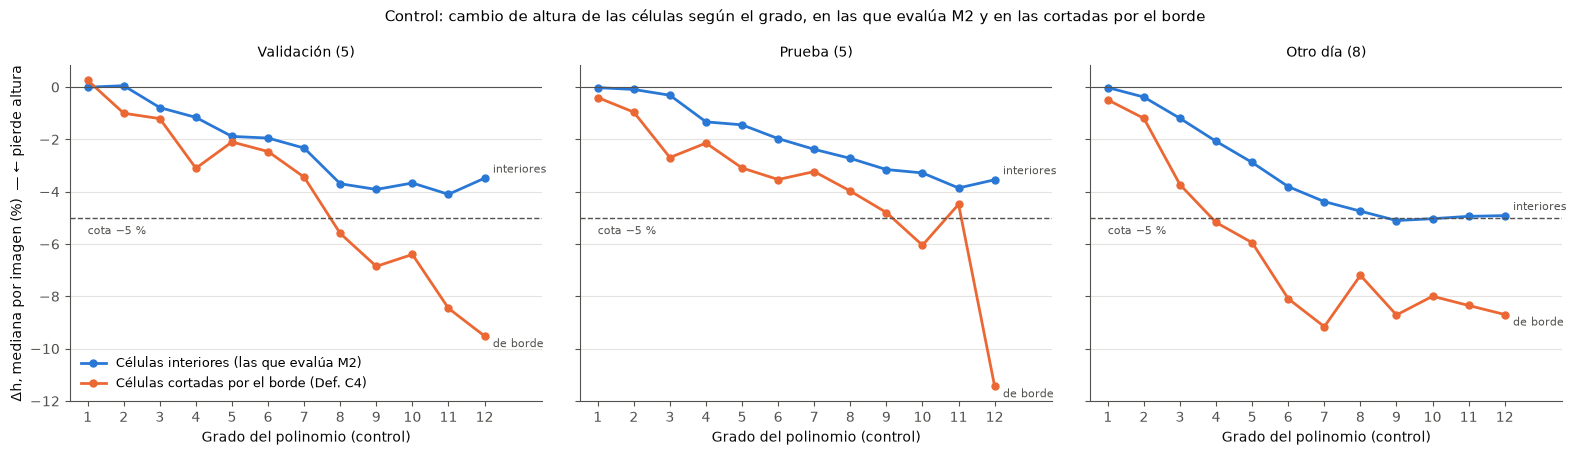

In [11]:
# 6.2 Figura: cambio de altura por grado del control, en células interiores (las que ve M2) y de borde
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for a, conj in zip(ax, CONJUNTOS):
    t = por_imagen[(por_imagen["método"] == CONTROL) & (por_imagen.conjunto == conj)].groupby(["grado", "tipo"])["Δh (%)"].median().unstack("tipo")
    a.plot(t.index, t["interior"], "-o", color=AZUL, ms=5, label="Células interiores (las que evalúa M2)")
    a.plot(t.index, t["borde"], "-o", color=NARANJA, ms=5, label="Células cortadas por el borde (Def. C4)")
    a.annotate("interiores", (12, t.loc[12, "interior"]), xytext=(6, 4), textcoords="offset points", fontsize=8, color=TINTA_2)
    a.annotate("de borde", (12, t.loc[12, "borde"]), xytext=(6, -8), textcoords="offset points", fontsize=8, color=TINTA_2)
    a.axhline(-5, color=TINTA_2, ls="--", lw=1); a.axhline(0, color=TINTA_2, lw=0.8)
    a.text(1, -5.3, "cota −5 %", fontsize=8, color=TINTA_2, va="top")
    a.set_title(ETIQUETA[conj][0].upper() + ETIQUETA[conj][1:])
    a.set_xlabel("Grado del polinomio (control)"); a.set_xticks(GRADOS); a.set_xlim(0.5, 13.6)
    a.grid(True, axis="y"); a.set_axisbelow(True)
ax[0].set_ylabel("Δh, mediana por imagen (%)  — ← pierde altura")
ax[0].legend(loc="lower left", frameon=False)
fig.suptitle("Control: cambio de altura de las células según el grado, en las que evalúa M2 y en las cortadas por el borde", fontsize=11)
fig.tight_layout(); plt.show()
guardar_figura(fig, "C3_altura_interior_vs_borde")

2021-01-29__13-06-43_3-12: peor célula de borde a grado 6, Δh = -42.1 %
2021-01-28__15-49-38_1-1: peor célula de borde a grado 6, Δh = -21.7 %


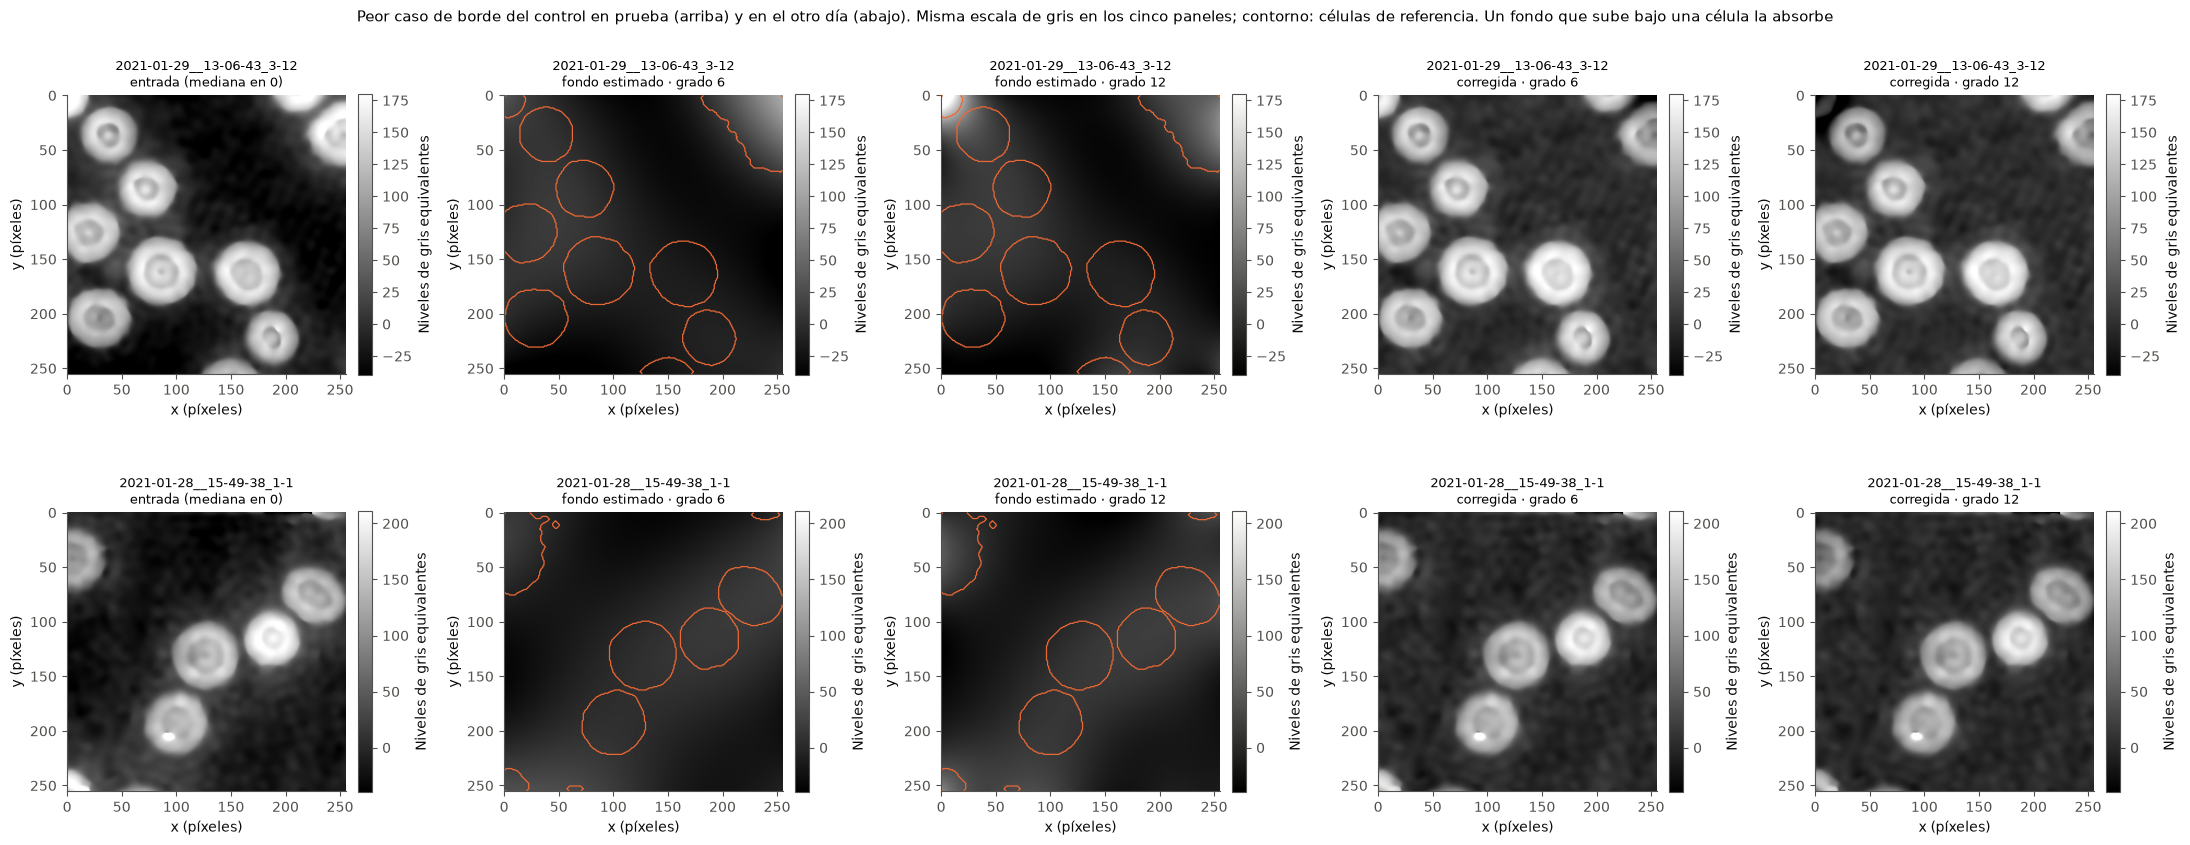

In [12]:
# 6.3 Inspección visual: en prueba y en el otro día, la imagen con la peor célula de borde del control a grado 6
archivos_fig = []
for conj in ("prueba", "generalizacion"):
    t = CELULAS[(CELULAS["método"] == CONTROL) & (CELULAS.grado == 6) & (CELULAS.tipo == "borde") & (CELULAS.conjunto == conj)]
    peor = t.loc[t["Δh (%)"].idxmin()]
    archivos_fig.append(("Image__" + peor.archivo + ".png", peor["Δh (%)"]))
fig, ax = plt.subplots(len(archivos_fig), 5, figsize=(22, 4.4 * len(archivos_fig)), squeeze=False)
for i, (f, peor_dh) in enumerate(archivos_fig):
    u = PREPROCESADAS[f]; cel = MASCARAS[f][0]; med = np.median(u)
    escala = dict(vmin=-40, vmax=float(np.percentile(u - med, 99.5)))
    b6, b12 = FONDOS[(f, 6)], FONDOS[(f, 12)]
    paneles = [(u - med, "entrada (mediana en 0)", False), (b6 - med, "fondo estimado · grado 6", True), (b12 - med, "fondo estimado · grado 12", True),
               (u - b6, "corregida · grado 6", False), (u - b12, "corregida · grado 12", False)]
    for j, (img, titulo, contorno) in enumerate(paneles):
        im = ax[i, j].imshow(img, **escala)
        cb = plt.colorbar(im, ax=ax[i, j], fraction=0.046, pad=0.04); cb.set_label("Niveles de gris equivalentes")
        if contorno:
            ax[i, j].contour(cel, levels=[0.5], colors=NARANJA, linewidths=0.9)
        ax[i, j].set_title(f"{f[7:-4]}\n{titulo}", fontsize=9)
        ax[i, j].set_xlabel("x (píxeles)"); ax[i, j].set_ylabel("y (píxeles)")
    print(f"{f[7:-4]}: peor célula de borde a grado 6, Δh = {peor_dh:.1f} %")
fig.suptitle("Peor caso de borde del control en prueba (arriba) y en el otro día (abajo). Misma escala de gris en los cinco paneles; "
             "contorno: células de referencia. Un fondo que sube bajo una célula la absorbe", fontsize=11)
fig.tight_layout(); plt.show()
guardar_figura(fig, "C3_inspeccion_fondos")

**Lectura de la salida (sección 6).**
- **M2 evalúa un tercio de las células.** De las 104 componentes de la máscara de referencia con al menos 600 píxeles, 36 son evaluables según la Definición 12 y 68 están cortadas por el borde.
- **La medida de borde no está dominada por el anillo parcial.** Con grado 1, que solo puede quitar una inclinación, 1 de las 68 células de borde cambia más del 3 %, y la peor cambia 3,7 %. Los cambios grandes de las filas siguientes no vienen del anillo incompleto.
- **El control absorbe células de borde, y M2 no lo registra** (tabla al final de esta lectura). Con grado 6, la mediana por imagen pasa de −2,0 % en las células interiores a −3,5 % en las de borde en prueba, y de −3,8 % a −8,1 % en el otro día. Con grado 12, de −3,5 % a −11,4 % en prueba.
- **También le ocurre a la línea base de la entrega.** El polinomio de grado 3 con recorte duro deja 16 de las 68 células de borde con más del 10 % de pérdida, y la peor pierde 44,3 %.
- **Figura 6.3.** En `13-06-43_3-12` el fondo estimado sube en la esquina superior derecha, bajo una célula que ocupa la esquina, y en la imagen corregida esa célula queda más oscura que las demás. Es la misma imagen en la que la entrega describe una franja de error de C en el borde derecho (9.3). En `15-49-38_1-1` ocurre lo mismo en la esquina superior izquierda.

| Control | Interiores con pérdida > 10 % (de 36) | De borde con pérdida > 10 % (de 68) | Peor célula de borde |
|---|---:|---:|---:|
| Grado 4 | 0 | 12 | −41,1 % |
| Grado 6 | 0 | 19 | −42,1 % |
| Grado 8 | 1 | 18 | −40,6 % |
| Grado 12 | 1 | 31 | −40,8 % |

**Qué se puede concluir y qué no.**

| Se puede concluir | No se puede concluir |
|---|---|
| El control con grado alto gana M1 a costa de células de borde que M2 no evalúa: su posición en la figura 4.3 es optimista | Que A o C absorban menos, o más, en los bordes: sus fondos no están versionados y no se pudo medir |
| El criterio de éxito de 6.5 y la regla de 8.5 no protegen a dos tercios de las células | La magnitud exacta en cada célula: el anillo es parcial y la Proposición 5 no aplica |

## 7. Cuánto de M1 es un desplazamiento constante

M1 es un RMS: $\mathrm{RMS}_{\text{lento}}^2 = \overline{\tilde v}^{\,2} + \operatorname{var}(\tilde v)$. Suma dos errores distintos: un **desplazamiento constante** del fondo corregido (que se quita restando un número) y su **forma** (que no). La entrega observa que C deja el fondo algo por encima de cero ($\mu_B = +2{,}30$ niveles en prueba, 9.1).

- Para el control se calcula la parte de forma **exacta**: la desviación estándar de $\tilde v$ sobre $B'$.
- Para los métodos publicados solo hay M1 y $\mu_B$ por imagen, así que se **estima** como $\sqrt{\mathrm{M1}^2 - \mu_B^2}$. No es exacto, porque $\mu_B$ se promedia sobre $B$ y M1 sobre $B'$. La celda mide el error de ese estimador en los ajustes del control, donde se conocen los dos valores.

In [13]:
# 7.1 M1 sin el desplazamiento constante: exacto para el control, estimado desde los CSV para lo publicado
filas = []
for conj in ("prueba", "generalizacion"):
    for f in ARCHIVOS[conj]:
        u = PREPROCESADAS[f]; fon = MASCARAS[f][1]
        for g in GRADOS:
            v = u - FONDOS[(f, g)]
            lento, valido = fondo_lento(v, fon)
            m1, mu = float(np.sqrt(np.mean(lento[valido] ** 2))), float(v[fon].mean())
            filas.append({"conjunto": conj, "archivo": f[7:-4], "grado": g, "M1": m1, "μ_B": mu, "M1 sin constante (exacto)": float(lento[valido].std()),
                          "M1 sin constante (estimado)": float(np.sqrt(max(m1 ** 2 - mu ** 2, 0.0)))})
PISTON = pd.DataFrame(filas)
PISTON["error del estimador"] = PISTON["M1 sin constante (estimado)"] - PISTON["M1 sin constante (exacto)"]
guardar_tabla(PISTON, "C4_desplazamiento_control_por_imagen")
err = PISTON["error del estimador"].abs()
print(f"Error del estimador √(M1² − μ_B²) en {len(PISTON)} ajustes del control: mediana {err.median():.3f}, percentil 95 {err.quantile(.95):.3f}, máximo {err.max():.3f} niveles")

GRADOS_TABLA = [4, 6, 8, 12]
tablas = {}
for conj in ("prueba", "generalizacion"):
    p = PUBLICADO[conj][PUBLICADO[conj]["método"].isin(REFERENCIAS)].copy()
    p["M1 sin constante"] = np.sqrt(np.clip(p[L] ** 2 - p["μ_B"] ** 2, 0, None))
    pub_t = p.groupby("método")[[L, "μ_B", "M1 sin constante"]].median().loc[REFERENCIAS].rename(columns={L: "M1"})
    pub_t.index = [f"{m} · estimado" for m in pub_t.index]
    c = PISTON[(PISTON.conjunto == conj) & PISTON.grado.isin(GRADOS_TABLA)].groupby("grado")[["M1", "μ_B", "M1 sin constante (exacto)"]].median()
    c = c.rename(columns={"M1 sin constante (exacto)": "M1 sin constante"}); c.index = [f"Control grado {g} · exacto" for g in c.index]
    tablas[ETIQUETA[conj]] = pd.concat([pub_t, c])
TABLA_PISTON = pd.concat(tablas, axis=1)
piston_plana = TABLA_PISTON.copy(); piston_plana.columns = [f"{m} · {c}" for c, m in piston_plana.columns]
guardar_tabla(piston_plana.reset_index(names="método"), "C4_desplazamiento_constante")
print("Medianas por imagen (niveles eq.)")
display(TABLA_PISTON.round(2))

filas = []
for conj in ("prueba", "generalizacion"):
    p = PUBLICADO[conj].copy(); p["sc"] = np.sqrt(np.clip(p[L] ** 2 - p["μ_B"] ** 2, 0, None))
    pv = p.pivot(index="archivo", columns="método", values="sc")
    for g in GRADOS:
        mio = PISTON[(PISTON.conjunto == conj) & (PISTON.grado == g)].set_index("archivo")["M1 sin constante (exacto)"]
        filas.append({"conjunto": ETIQUETA[conj], "grado": g, **{f"menos que {r}": f"{int((mio < pv[r]).sum())}/{len(mio)}" for r in REFERENCIAS}})
    z = pv["Zernike (guía)"]
    print(f"{ETIQUETA[conj]}: sin la constante (estimado), C deja menos fondo lento que el Zernike en {int((pv['INR condicionada (C)'] < z).sum())} de {len(z)} imágenes "
          f"y A en {int((pv['SIREN por imagen + física (A)'] < z).sum())} de {len(z)}")
SIN_CONSTANTE = pd.DataFrame(filas)
guardar_tabla(SIN_CONSTANTE, "C4_sin_constante_por_imagen")
print("Imágenes en que el control deja menos fondo lento que cada método publicado, quitando la constante en ambos")
display(SIN_CONSTANTE.pivot(index="grado", columns="conjunto"))

Error del estimador √(M1² − μ_B²) en 156 ajustes del control: mediana 0.053, percentil 95 0.210, máximo 0.718 niveles
Medianas por imagen (niveles eq.)


prueba (5)                        otro día (8)                       
                                                 M1   μ_B M1 sin constante           M1   μ_B M1 sin constante
Zernike (guía) · estimado                      6.49 -0.27             6.48         5.98 -0.06             5.95
INR condicionada (C) · estimado                6.70  2.30             5.63         4.88  0.93             4.74
SIREN por imagen + física (A) · estimado       4.76  0.86             4.68         3.74  0.19             3.74
C + ajuste fino (100 it.) · estimado           5.12  1.52             4.87         3.83  0.58             3.78
Control grado 4 · exacto                       6.82  2.36             6.65         6.22  1.22             6.12
Control grado 6 · exacto                       5.96  1.74             5.75         4.66  0.76             4.60
Control grado 8 · exacto                       5.49  1.46             5.37         3.82  0.59             3.79
Control grado 12 · exacto                      4.43  1.26             4.31         3.50  0.50             3.47

prueba (5): sin la constante (estimado), C deja menos fondo lento que el Zernike en 5 de 5 imágenes y A en 5 de 5
otro día (8): sin la constante (estimado), C deja menos fondo lento que el Zernike en 7 de 8 imágenes y A en 8 de 8
Imágenes en que el control deja menos fondo lento que cada método publicado, quitando la constante en ambos


menos que Zernike (guía)            menos que INR condicionada (C)            menos que SIREN por imagen + física (A)            menos que C + ajuste fino (100 it.)           
conjunto             otro día (8) prueba (5)                   otro día (8) prueba (5)                            otro día (8) prueba (5)                        otro día (8) prueba (5)
grado                                                                                                                                                                                   
1                             0/8        0/5                            0/8        0/5                                     0/8        0/5                                 0/8        0/5
2                             0/8        0/5                            1/8        0/5                                     0/8        0/5                                 0/8        0/5
3                             1/8        0/5                            1/8        0/5                                     1/8        0/5                                 1/8        0/5
4                             5/8        0/5                            0/8        0/5                                     0/8        0/5                                 0/8        0/5
5                             8/8        2/5                            3/8        0/5                                     1/8        0/5                                 1/8        0/5
6                             8/8        5/5                            6/8        4/5                                     1/8        0/5                                 1/8        0/5
7                             8/8        5/5                            8/8        4/5                                     1/8        0/5                                 1/8        0/5
8                             8/8        5/5                            8/8        5/5                                     1/8        3/5                                 4/8        3/5
9                             8/8        5/5                            8/8        5/5                                     5/8        3/5                                 8/8        4/5
10                            8/8        5/5                            8/8        5/5                                     8/8        3/5                                 8/8        4/5
11                            8/8        5/5                            8/8        5/5                                     8/8        4/5                                 8/8        4/5
12                            8/8        5/5                            8/8        5/5                                     8/8        4/5                                 8/8        5/5

**Lectura de la salida (sección 7).**
- **El estimador es utilizable.** En los 156 ajustes del control, $\sqrt{\mathrm{M1}^2 - \mu_B^2}$ difiere del valor exacto en 0,05 niveles de mediana, 0,21 en el percentil 95 y 0,72 como máximo.
- **El desplazamiento positivo aparece también sin red.** Con grados 4, 6, 8 y 12, el control deja $\mu_B$ de +2,36, +1,74, +1,46 y +1,26 niveles en prueba, del mismo signo y tamaño que C (+2,30). El Zernike del código guía, con otra pérdida, deja −0,27. Es consistente con que el desplazamiento venga de la pérdida y no del modelo. La ablación de la sección 8 identifica el término responsable.
- **Sin la constante, C deja menos fondo lento que el Zernike.** La mediana estimada de C en prueba baja de 6,70 a 5,63 niveles, frente a 6,48 del Zernike, y queda por debajo en 5 de 5 imágenes de prueba y en 7 de 8 del otro día. La diferencia de 0,21 niveles por la que C no cumple la condición 2 del criterio de 6.5 es de desplazamiento, no de forma. Restar una constante después de la inferencia no cambia M2 (Proposición 5).
- **Sin la constante, el control y C quedan más cerca.** En prueba, el grado 6 deja 5,75 niveles (exacto) frente a 5,63 de C (estimado), menos que C en 4 de 5 imágenes; el grado 8 deja 5,37, menos en 5 de 5. La ventaja en M1 del grado 6 sobre C de la sección 4 se debe en parte a que C tiene un desplazamiento mayor. La diferencia en M2 no depende de la constante.

**Límite:** las cifras de los métodos publicados son estimadas. Calcularlas de forma exacta requiere sus fondos. Recentrar C y volver a evaluar en prueba sería un cambio posterior a mirar la prueba, y habría que declararlo.

## 8. Ablación determinista de la pérdida

En la entrega, la ablación de la exclusión por vecindad quedó dentro de la variación entre semillas (H4.2: 0,85 puntos frente a una variación de 0,42; "no se puede afirmar que sea un aporte claro"). El control no tiene semilla ni muestreo, así que cada cambio de la pérdida se mide sin ese ruido. Se repite con grado 6 y grado 10, cambiando un solo elemento cada vez, igual que en 8.6 y 8.7.1 de la entrega.

Las diferencias entre filas no tienen ruido de optimización, pero siguen siendo medianas sobre 5, 5 y 8 imágenes.

In [14]:
# 8.1 Ablación: un cambio a la vez sobre la pérdida completa, con grado 6 y grado 10
VARIANTES = {"completa": {},
             "sin exclusión por vecindad": dict(vecindad=False),
             "sin recorte ni vecindad (Charbonnier completa)": dict(recorte=False, vecindad=False),
             "sin signo": dict(signo=False),
             "sin suavidad (λ_s = 0)": dict(lam_s=0.0),
             "λ_s × 10": dict(lam_s=10 * LAMBDA_S),
             "κ = 2": dict(kappa=2.0), "κ = 4": dict(kappa=4.0),
             "vecindad d = 12": dict(d=12)}
filas = []
for conj in CONJUNTOS:
    for f in ARCHIVOS[conj]:
        u = PREPROCESADAS[f]
        for g in (6, 10):
            for nombre, cambios in VARIANTES.items():
                b = FONDOS[(f, g)] if not cambios else ajuste_fisico(u, g, **cambios)
                filas.append({"conjunto": conj, "archivo": f[7:-4], "grado": g, "variante": nombre, **metricas_archivo(u - b, f)})
ABLACION = pd.DataFrame(filas)
guardar_tabla(ABLACION, "C5_ablacion_por_imagen")
RESUMEN_ABL = ABLACION.groupby(["grado", "variante", "conjunto"], sort=False)[[L, ADH]].median().unstack("conjunto")
RESUMEN_ABL = RESUMEN_ABL.reindex(columns=[(m, c) for c in CONJUNTOS for m in (L, ADH)])
RESUMEN_ABL.columns = [f"{'M1' if m == L else 'M2 (%)'} · {ETIQUETA[c]}" for m, c in RESUMEN_ABL.columns]
guardar_tabla(RESUMEN_ABL.reset_index(), "C5_ablacion")
display(RESUMEN_ABL.round(2))
MU_ABL = ABLACION.groupby(["grado", "variante", "conjunto"], sort=False)["μ_B"].median().unstack("conjunto")[CONJUNTOS]
MU_ABL.columns = [f"μ_B · {ETIQUETA[c]}" for c in MU_ABL.columns]
guardar_tabla(MU_ABL.reset_index(), "C5_ablacion_mu_B")
print("Media del fondo corregido, μ_B (niveles eq.; mediana por imagen), para las mismas variantes")
display(MU_ABL.round(2))

M1 · validación (5)  M2 (%) · validación (5)  M1 · prueba (5)  M2 (%) · prueba (5)  M1 · otro día (8)  M2 (%) · otro día (8)
grado variante                                                                                                                                                                    
6     completa                                                       5.76                     1.95             5.96                 1.97               4.66                   3.81
      sin exclusión por vecindad                                     5.49                     2.47             6.23                 2.43               4.65                   4.45
      sin recorte ni vecindad (Charbonnier completa)                11.86                     4.10            12.05                 4.67               8.64                   6.44
      sin signo                                                      5.76                     1.95             5.96                 1.97               4.66                   3.81
      sin suavidad (λ_s = 0)                                         5.11                     3.76             5.03                 3.61               3.82                   6.16
      λ_s × 10                                                       6.71                     0.63             7.94                 0.78               6.86                   1.56
      κ = 2                                                          6.25                     1.73             7.13                 1.69               5.54                   3.64
      κ = 4                                                          5.57                     2.03             6.13                 2.08               4.52                   3.87
      vecindad d = 12                                                7.49                     1.13             8.07                 1.53               5.91                   2.98
10    completa                                                       4.53                     3.67             4.75                 3.28               3.56                   5.03
      sin exclusión por vecindad                                     4.51                     5.16             4.34                 4.69               3.61                   6.66
      sin recorte ni vecindad (Charbonnier completa)                 9.70                     9.13            10.54                 7.53               7.10                  10.51
      sin signo                                                      4.41                     3.67             4.75                 3.29               3.56                   5.03
      sin suavidad (λ_s = 0)                                         4.04                    14.04            14.58                12.46               3.99                  11.93
      λ_s × 10                                                       7.17                     0.87             7.34                 1.16               5.89                   1.90
      κ = 2                                                          5.14                     2.86             5.75                 3.14               4.04                   4.64
      κ = 4                                                          4.32                     4.38             4.32                 3.55               3.45                   5.35
      vecindad d = 12                                                7.65                     1.70             7.33                 2.24               4.70                   3.64

Media del fondo corregido, μ_B (niveles eq.; mediana por imagen), para las mismas variantes


μ_B · validación (5)  μ_B · prueba (5)  μ_B · otro día (8)
grado variante                                                                                                  
6     completa                                                        2.26              1.74                0.76
      sin exclusión por vecindad                                     -0.66             -0.63               -0.76
      sin recorte ni vecindad (Charbonnier completa)                 -5.71             -4.62               -3.04
      sin signo                                                       2.26              1.74                0.76
      sin suavidad (λ_s = 0)                                          1.52              0.99                0.37
      λ_s × 10                                                        2.46              2.70                1.65
      κ = 2                                                           3.07              3.07                1.84
      κ = 4                                                           1.81              1.26                0.53
      vecindad d = 12                                                 4.56              4.29                2.18
10    completa                                                        1.52              1.18                0.50
      sin exclusión por vecindad                                     -0.56             -0.74               -0.62
      sin recorte ni vecindad (Charbonnier completa)                 -3.97             -3.67               -2.32
      sin signo                                                       1.48              1.18                0.50
      sin suavidad (λ_s = 0)                                          0.66              2.54                0.59
      λ_s × 10                                                        2.47              2.11                1.08
      κ = 2                                                           2.25              2.01                1.03
      κ = 4                                                           1.23              0.80                0.34
      vecindad d = 12                                                 3.99              3.36                1.64

**Lectura de la salida (sección 8).** Cambios de M2 en validación / prueba / otro día.

- **El recorte es decisivo**, como en 8.6 de la entrega. Sin recorte ni exclusión, M1 se duplica (grado 6: de 5,76 a 11,86 niveles en validación) y M2 sube (de 1,95 a 4,10 %).
- **La exclusión por vecindad sí reduce la absorción.** Sin ella, M2 sube en los tres conjuntos y con los dos grados: 0,52 / 0,46 / 0,64 puntos con grado 6 y 1,49 / 1,41 / 1,63 con grado 10. M1 cambia menos de 0,5 niveles y sin dirección consistente. La entrega midió 0,85 puntos con C y no pudo separarlo de la variación entre semillas (H4.2); aquí no hay semilla y la dirección es la misma en las seis comparaciones.
- **La exclusión por vecindad es también la que desplaza el fondo.** Con grado 6, $\mu_B$ vale +2,26 / +1,74 / +0,76 niveles con la pérdida completa y −0,66 / −0,63 / −0,76 sin la exclusión; con $d = 12$ sube a +4,56 / +4,29 / +2,18. El término de datos lleva a cero la mediana del residuo solo en los píxeles con peso 1, y los entornos que se excluyen son los de residuos positivos. La exclusión reduce la absorción a cambio de un fondo corregido desplazado hacia arriba, que se puede recentrar después (sección 7).
- **El término de signo no cambia nada.** Las métricas difieren en 0,01 puntos o menos con y sin él, salvo 0,12 niveles de M1 en validación con grado 10. Es consistente con la ablación de la versión 1 de la entrega (8.2).
- **La suavidad es el regulador principal.** Sin ella, el grado 10 absorbe 14,04 / 12,46 / 11,93 %. Con $\lambda_s \times 10$, M2 baja a 0,87 / 1,16 / 1,90 % y M1 sube a 7,17 / 7,34 / 5,89 niveles.
- **$\kappa$ y $d$ mueven el compromiso en la misma dirección que en la entrega** (8.7.1): $\kappa = 2$ y $d = 12$ protegen la célula y dejan más fondo.

Los diales de la entrega se comportan igual sobre una base polinomial. Es consistente con que el compromiso fondo–célula lo gobierne la pérdida.

## 9. Un mínimo degenerado de la pérdida

En la Definición 17 el término de datos se promedia solo sobre los píxeles con peso $w_i = 1$. Si el fondo propuesto baja tanto que **todos** los residuos superan $\tau$, todos los píxeles quedan excluidos, la suma de pesos vale 0 y el término de datos vale 0. El término de signo también vale 0, porque los residuos son positivos. Solo queda la suavidad.

La celda toma el fondo ajustado por el control (grado 3) en las 5 imágenes de validación, lo desplaza hacia abajo y evalúa la pérdida.

In [15]:
# 9.1 Pérdida física al desplazar hacia abajo un fondo bien ajustado (validación, grado 3)
filas = []
Q3, LAP3 = BASES[3]
tau = TAU_NG / ESCALA_NG
for f in ARCHIVOS["validacion"]:
    u = PREPROCESADAS[f]; med = float(np.median(u))
    x = ((u - med) / ESCALA_NG).ravel()
    c = Q3.T @ ((FONDOS[(f, 3)] - med) / ESCALA_NG).ravel()
    for bajada in (0, 16, 32, 64, 128):
        perdida, frac = perdida_fisica(x - (Q3 @ c - bajada / ESCALA_NG), LAP3 @ c, tau)
        filas.append({"archivo": f[7:-4], "fondo desplazado hacia abajo (niveles)": bajada, "pérdida": perdida, "píxeles con peso 1 (%)": 100 * frac})
DEGENERADO = pd.DataFrame(filas)
guardar_tabla(DEGENERADO, "C6_minimo_degenerado_por_imagen")
RESUMEN_DEG = DEGENERADO.groupby("fondo desplazado hacia abajo (niveles)")[["pérdida", "píxeles con peso 1 (%)"]].median()
guardar_tabla(RESUMEN_DEG.reset_index(), "C6_minimo_degenerado")
print("Medianas sobre las 5 imágenes de validación")
display(RESUMEN_DEG.round(4))

Medianas sobre las 5 imágenes de validación


,pérdida,píxeles con peso 1 (%)
fondo desplazado hacia abajo (niveles),,
0,0.1216,59.6069
16,0.2378,54.0833
32,0.4162,33.4229
64,0.0023,0.0000
128,0.0023,0.0000


**Lectura de la salida (sección 9).**
- En el fondo ajustado, la pérdida mediana es 0,1216, con el 59,6 % de los píxeles con peso 1.
- Al bajar el fondo 16 y 32 niveles la pérdida **sube** a 0,2378 y 0,4162: es la barrera que mantiene al optimizador en la solución útil.
- Al bajarlo 64 niveles o más, ningún píxel conserva peso y la pérdida cae a 0,0023, unas 50 veces menos que en la solución útil. Solo queda el término de suavidad.

**Consecuencias.**
1. La Definición 17 tiene un mínimo global degenerado, separado de la solución útil por una barrera. El calentamiento ayuda a empezar del lado correcto, pero la pérdida no lo garantiza. Es un mecanismo compatible con el "descontrol" de A en la versión 1 (125 niveles de fondo lento en una imagen de prueba, 8.2).
2. La entrega guarda el estado con menor pérdida de validación (8.3). Un modelo que excluye más píxeles promedia sobre menos, de modo que esa pérdida no es comparable entre modelos con máscaras distintas, y un colapso la minimizaría.
3. Una corrección posible es dividir por el número total de píxeles y hacer que cada píxel excluido aporte $\rho_\epsilon(\tau)$, igual que los recortados. Así excluir deja de ser gratis y el mínimo degenerado desaparece. No se evaluó aquí.

## 10. Datos disponibles para una evaluación ciega

La entrega declara dos límites: pocas imágenes de evaluación y una prueba que dejó de ser ciega (12.3). La celda cuenta, con las tablas ya versionadas de la sección 3.5 de la entrega, cuántas adquisiciones del 29/01 pasan **el mismo filtro automático** con el que se generaron las candidatas y nunca se mostraron al grupo ni se usaron.

In [16]:
# 10.1 Adquisiciones del 29/01 que pasan el filtro de 3.5.4 de la entrega y no se han usado
cand = pd.read_csv(TABLAS_ENTREGA / "E1_metricas_candidatos.csv")
mostrados = pd.read_csv(SELECTION_DIR / "candidatos_mostrados.csv")
dia = cand[cand.adq.str.startswith("2021-01-29")]
filtro = dia[(dia.res_saltos <= 2) & (dia.saltos_fondo == 0) & (dia.completas >= 2) & dia.frac_cel.between(0.05, 0.40) & (dia.signo == -1)]
con_estilo = filtro[filtro.gris_fondo.between(90, 150) & (filtro.gris_celula >= 175)]
usadas = set(SELECCION[SELECCION.conjunto != "generalizacion"].ts)
SIN_USAR = pd.DataFrame({"Adquisiciones": {
    "Del 29/01 en el dataset": dia.adq.nunique(),
    "Pasan el filtro automático": filtro.adq.nunique(),
    "Pasan además el filtro de estilo": con_estilo.adq.nunique(),
    "Mostradas al grupo (candidatos_mostrados.csv)": mostrados.ts.nunique(),
    "Usadas en entrenamiento, validación o prueba": len(usadas),
    "Pasan filtro y estilo y nunca se mostraron ni usaron": len(set(con_estilo.adq) - set(mostrados.ts) - usadas),
    "Pasan el filtro automático (sin el de estilo) y nunca se mostraron ni usaron": len(set(filtro.adq) - set(mostrados.ts) - usadas)}})
assert set(mostrados.ts) <= set(con_estilo.adq), "Las candidatas mostradas deberían salir del mismo filtro"
guardar_tabla(SIN_USAR.reset_index(names="Aspecto"), "C7_adquisiciones_sin_usar")
SIN_USAR

,Adquisiciones
Del 29/01 en el dataset,187
Pasan el filtro automático,134
Pasan además el filtro de estilo,76
Mostradas al grupo (candidatos_mostrados.csv),40
"Usadas en entrenamiento, validación o prueba",22
Pasan filtro y estilo y nunca se mostraron ni usaron,36
Pasan el filtro automático (sin el de estilo) y nunca se mostraron ni usaron,94


**Lectura de la salida (sección 10).** De las 187 adquisiciones del 29/01, 134 pasan el filtro automático y 76 pasan además el de estilo. De esas 76 se mostraron 40 al grupo y se usaron 22. Quedan **36 adquisiciones** que pasan los dos filtros y nunca se mostraron ni se usaron, y 94 si se prescinde del filtro de estilo. Las máscaras de referencia y las métricas son automáticas, así que evaluar ahí no requiere anotar nada.

Dos precauciones:
- Esas 36 no pasaron la curación visual de 3.6 de la entrega, así que pueden incluir polvo o artefactos que la selección descartó.
- Calcular sus métricas requiere el dataset completo (`data/raw/`), que este notebook no usa.

Del 28/01 el dataset solo tiene 5 adquisiciones y la entrega ya usa 3 (3.2 y 3.6 de la entrega).

## 11. Conclusiones y límites

### 11.1 Hallazgos

1. **Con M1 y M2, la INR no se distingue de un polinomio ajustado con su misma pérdida.** La curva del control pasa por los puntos de A y queda por debajo de los de C en los tres conjuntos (4.3, 5.1). En el espacio del Zernike del código guía, la pérdida física reduce el cambio de altura a alrededor de la mitad con 0,2 a 0,3 niveles más de fondo.
2. **Es consistente con que el aporte medible de la entrega sea la pérdida física.** Refuerza su hallazgo 4 ("las restricciones físicas reducen la absorción unas 4 veces") y matiza el 5: en M1 y M2, la calidad de C se alcanza con 28 coeficientes ajustados por imagen. La ventaja de C que este control no toca es que no ajusta nada por imagen.
3. **M2 deja fuera 68 de las 104 células, y ahí el control absorbe** (6.1). Ni el criterio de éxito de 6.5 ni la regla de selección de 8.5 lo detectan. Para A, C y el Zernike no está medido.
4. **Parte de M1 es un desplazamiento constante que introduce la exclusión por vecindad** (secciones 7 y 8). Sin él, C deja menos fondo lento que el Zernike en prueba (estimado: 5,63 frente a 6,48 niveles).
5. **Sin ruido de semillas, la exclusión por vecindad reduce el cambio de altura** entre 0,5 y 1,6 puntos, el signo no cambia nada y la suavidad es el regulador principal (sección 8).
6. **La pérdida tiene un mínimo degenerado** en el que todos los píxeles quedan excluidos (sección 9).

### 11.2 Límites

- **No es una evaluación ciega.** El control se diseñó después de la entrega, con prueba y el otro día ya examinados, y sobre las mismas 5, 5 y 8 imágenes.
- **Pocas imágenes.** Con 5 imágenes ninguna prueba pareada alcanza significancia al 5 %. Las tres adquisiciones del otro día no son 8 muestras independientes.
- **El control no es un método propuesto.** Absorbe células de borde y no converge en todas las imágenes a partir de grado 7.
- **No es amortizado.** Ajusta cada imagen, como A y el Zernike. No dice nada sobre el costo de inferencia de C.
- **Las cifras de la sección 7 para los métodos publicados son estimadas** a partir de M1 y $\mu_B$.
- **La medida de borde usa un anillo parcial** y se definió después de ver los resultados.

### 11.3 Qué haría falta para cerrar la pregunta

1. **Guardar los fondos estimados por A, C y el Zernike** en las 18 imágenes de evaluación y calcular sobre ellos la medida de borde de la sección 6 y el M1 sin constante de la sección 7.
2. **Una prueba ciega más grande.** Hay 36 adquisiciones del 29/01 que pasan los mismos filtros que la selección y nunca se mostraron ni se usaron (sección 10). Evaluar ahí, una sola vez, el modelo final congelado, el Zernike y este control con un grado fijado de antemano.
3. **Añadir las células de borde al criterio de éxito** antes de esa evaluación.
4. **Corregir el promedio de la pérdida** (9, consecuencia 3) y recentrar el fondo corregido, y medir de nuevo.